# Probability of Default Model for Consumer Credit Risk

**LendingClub 36-month loans | WoE logistic scorecard with machine learning challengers | out-of-time validation**

An application scorecard that estimates the lifetime probability of default for 36-month LendingClub loans using only information available at the point of application. The model is trained on loans originated in 2013 and 2014 and validated out-of-time on 372,811 loans originated between January 2015 and March 2016.

### Key results (out-of-time test)

| Metric | Result |
|---|---|
| Champion: WoE logistic scorecard | AUC 0.676, Gini 0.353, KS 0.254 |
| Challenger: tuned XGBoost | AUC 0.695, Gini 0.390 |
| Score stability (PSI, train vs test) | 0.002 |
| Bad rate at a 70% approval rate | 10.9%, against 15.2% for the whole book (50% of defaults avoided) |
| Share of defaults in the riskiest 30% of applicants | 49.8% |
| Expected loss and Basel IRB capital | 12.0% and 10.2% of exposure |

### Design choices

- **Right-censoring control:** only loans whose full term ended before the data cutoff are used, so every outcome is observed.
- **Leakage control:** LendingClub's grade and interest rate and all post-origination fields are excluded from the model. Section 22 shows that adding post-origination fields would raise AUC to 0.95 or above, a result no lender could achieve at the point of decision.
- **Out-of-time validation:** all binning, feature selection and tuning use training data only, with time-based cross-validation.
- **Champion and challengers:** an interpretable scorecard compared with a decision tree, random forest and tuned XGBoost.
- **From PD to money:** cut-off selection, risk bands, recalibration, expected loss and Basel capital.

### Contents

| # | Section | # | Section |
|---|---|---|---|
| 1 | Business problem | 13 | Hyperparameter tuning and time-based cross-validation |
| 2 | Data | 14 | Final model comparison |
| 3 | Modelling universe (right-censoring) | 15 | Cut-off selection |
| 4 | Target definition | 16 | Calibration and stability |
| 5 | Leakage controls | 17 | Recalibration |
| 6 | Out-of-time split | 18 | Explainability |
| 7 | Exploratory data analysis | 19 | Scorecard points |
| 8 | Feature engineering | 20 | Risk bands |
| 9 | Binning, WoE and IV | 21 | Expected loss and Basel capital |
| 10 | Multicollinearity and the logistic scorecard | 22 | Benchmarking and leakage test |
| 11 | Baseline models | 23 | Limitations and next steps |
| 12 | Class imbalance | 24 | Model artefacts and scoring function |

## 1. Business problem

A consumer lender must decide, for every application, whether to approve the loan and at what price. Approving a borrower who later defaults loses most of the outstanding principal; declining a borrower who would have repaid loses the interest income.

A **Probability of Default (PD)** model estimates, using only information available at application, the probability that a borrower defaults over the life of the loan. Lenders use the PD for:

- **Approval decisions:** decline or refer high-PD applicants
- **Risk-based pricing:** charge riskier borrowers more
- **Provisions and capital:** Basel IRB and IFRS 9 combine PD with LGD and EAD, where **Expected Loss = PD × LGD × EAD**

**Framing:** supervised binary classification with a probability output (`1` = default, `0` = repaid).

**Success criteria**

| Criterion | Measures |
|---|---|
| Ranking power | AUC, Gini, KS |
| Accuracy of the probabilities | Calibration by decile, Brier score |
| Business value | Bad rate at each approval rate, defaults avoided |
| Interpretability | Monotonic, explainable drivers for every decline |

In [1]:
# Colab: xgboost and shap are usually pre-installed
!pip install -q kagglehub xgboost shap imbalanced-learn

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.special import logit as log_odds, expit   # log_odds(p) = ln(p / (1 - p)); expit is its inverse
from scipy.stats import norm

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_score, recall_score)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import joblib

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
sns.set_style('whitegrid')
SEED = 42

os.makedirs('images', exist_ok=True)
def save(name):
    # Save the current chart for the README
    plt.savefig(f'images/{name}.png', dpi=110, bbox_inches='tight')

## 2. Data

**Source:** LendingClub accepted-loans file on Kaggle (`wordsforthewise/lending-club`), about 2.26 million loans issued between 2007 and 2018 with 151 columns. The latest payment activity in the file is **March 2019**, which is the observation cutoff.

Only the columns needed are loaded:

| Group | Purpose |
|---|---|
| Application-time numeric and categorical fields | Candidate model features |
| `loan_status`, `issue_d`, `term`, `earliest_cr_line` | Target, time split, scope and feature engineering |
| `grade`, `int_rate` | Benchmarking only (section 22), never model inputs |
| Payment and recovery fields | Loss measurement (section 21) and the leakage test (section 22), never model inputs |

In [3]:
import kagglehub

path = kagglehub.dataset_download('wordsforthewise/lending-club')
FILE = os.path.join(path, 'accepted_2007_to_2018Q4.csv.gz')
print('Data file:', FILE)

Data file: /root/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/accepted_2007_to_2018Q4.csv.gz


In [4]:
# Application-time candidates: loan request, income, affordability and credit bureau fields
NUM_COLS = ['loan_amnt', 'annual_inc', 'dti', 'fico_range_low', 'revol_util', 'revol_bal',
            'inq_last_6mths', 'mths_since_recent_inq', 'acc_open_past_24mths', 'mort_acc',
            'avg_cur_bal', 'open_acc', 'total_acc', 'delinq_2yrs', 'pub_rec',
            'pub_rec_bankruptcies', 'bc_util', 'percent_bc_gt_75', 'num_tl_op_past_12m',
            'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_tl', 'num_actv_rev_tl', 'tot_cur_bal',
            'tot_hi_cred_lim', 'total_bc_limit', 'bc_open_to_buy', 'total_bal_ex_mort',
            'mths_since_recent_bc', 'mths_since_last_delinq', 'pct_tl_nvr_dlq',
            'num_accts_ever_120_pd']
CAT_COLS = ['term', 'home_ownership', 'verification_status', 'purpose', 'emp_length']
CAT_FEATS = ['home_ownership', 'verification_status', 'purpose', 'emp_length']   # term is constant after scoping

# Target, split, feature engineering and benchmarking (never model inputs)
OTHER_COLS = ['issue_d', 'loan_status', 'earliest_cr_line', 'grade', 'int_rate']

# Created after the loan was issued: loss measurement and leakage test only (never model inputs)
POST_COLS = ['funded_amnt', 'total_rec_prncp', 'recoveries', 'collection_recovery_fee',
             'total_pymnt', 'last_fico_range_high']

USE_COLS = NUM_COLS + CAT_COLS + OTHER_COLS + POST_COLS
print(f'Loading {len(USE_COLS)} of 151 columns')

Loading 47 of 151 columns


## 3. Modelling universe (right-censoring)

A loan's outcome is known only once its term has ended. A 36-month loan issued in 2017 was still running in March 2019, so it appears in the file as a default only if it had already defaulted, and as repaid only if it had prepaid early. Including such loans biases the sample towards fast outcomes (**right-censoring**).

**Rule:** keep a loan only if `issue date + term ≤ 2019-03-01`. The file is read in chunks so the full 2.26 million rows are never held in memory.

In [5]:
CUTOFF = pd.Timestamp('2019-03-01')

chunks, n_total = [], 0
for chunk in pd.read_csv(FILE, usecols=USE_COLS, chunksize=250_000, low_memory=False):
    n_total += len(chunk)
    chunk['issue_d'] = pd.to_datetime(chunk['issue_d'], format='%b-%Y', errors='coerce')
    chunk['term_months'] = chunk['term'].str.extract(r'(\d+)')[0].astype(float)
    chunk = chunk.dropna(subset=['issue_d', 'term_months'])

    # Contractual end date of each loan
    end_36 = chunk['issue_d'] + pd.DateOffset(months=36)
    end_60 = chunk['issue_d'] + pd.DateOffset(months=60)
    term_end = end_36.where(chunk['term_months'] == 36, end_60)

    chunks.append(chunk[term_end <= CUTOFF])

df = pd.concat(chunks, ignore_index=True)
print(f'All loans in file      : {n_total:,}')
print(f'Fully observable loans : {len(df):,} ({len(df) / n_total:.1%})')

All loans in file      : 2,260,701
Fully observable loans : 785,915 (34.8%)


## 4. Target definition

| Label | `loan_status` values |
|---|---|
| **Bad = 1** | Charged Off; Default; Does not meet the credit policy. Status:Charged Off |
| **Good = 0** | Fully Paid; Does not meet the credit policy. Status:Fully Paid |
| Excluded | Current, In Grace Period, Late (unresolved, under 1% of the universe) |

The target is **lifetime default** because the file records whether a loan defaulted but not when.

**Scope: 36-month loans.** Fully observed 60-month loans end in early 2014, which leaves no later period for an out-of-time test. Lenders also build separate scorecards per product.

In [6]:
BAD = ['Charged Off', 'Default', 'Does not meet the credit policy. Status:Charged Off']
GOOD = ['Fully Paid', 'Does not meet the credit policy. Status:Fully Paid']

df = df[df['loan_status'].isin(BAD + GOOD)].copy()
df['target'] = df['loan_status'].isin(BAD).astype(int)
df = df[df['term_months'] == 36].copy()

print(f'Modelling universe (36-month) : {len(df):,}')
print(f'Bad rate                      : {df["target"].mean():.2%}')

Modelling universe (36-month) : 710,807
Bad rate                      : 14.22%


## 5. Leakage controls

Target leakage means training on information that would not exist at the time of the decision. It produces excellent test scores and a model that cannot be used. Every column was classified before modelling:

| Class | Examples | Treatment |
|---|---|---|
| Known at application | income, employment, home ownership, purpose, DTI, loan amount, FICO, inquiries, account history, utilisation, bureau balances and limits | Model candidates |
| LendingClub's own risk output | grade, sub_grade, int_rate, installment | Excluded; the model should be an independent view of risk. Used only for benchmarking in section 22 |
| Created after issue | total_pymnt, total_rec_prncp, recoveries, collection_recovery_fee, last_fico_range_high | Excluded. Used only to measure losses on defaulted loans (section 21) and to quantify leakage (section 22) |
| Target source and split key | loan_status, issue_d | Target construction and time split only |

The model input lists (`NUM_FEATS`, `CAT_FEATS`) are defined explicitly, so no excluded column can enter a model by accident.

## 6. Out-of-time split

The model will score future applicants, so it is trained on earlier loans and tested on later ones. The split is made **before** any analysis, and all EDA, binning and fitting use the training data only.

| Set | Origination period |
|---|---|
| Train | Jan 2013 to Dec 2014 |
| Test (out-of-time) | Jan 2015 to Mar 2016 |

Loans before 2013 are excluded: around half of the bureau fields used here were not recorded for 2012 loans, and earlier vintages are small.

In [7]:
train = (df[df['issue_d'].dt.year.between(2013, 2014)]
         .sort_values('issue_d')          # sorted by date for time-based cross-validation
         .reset_index(drop=True)
         .copy())
test = (df[(df['issue_d'] >= '2015-01-01') & (df['issue_d'] <= '2016-03-01')]
        .reset_index(drop=True)
        .copy())

y_train, y_test = train['target'], test['target']
print(f'Train: {len(train):,} loans, bad rate {y_train.mean():.2%}')
print(f'Test : {len(test):,} loans, bad rate {y_test.mean():.2%}')

Train: 262,992 loans, bad rate 13.19%
Test : 372,811 loans, bad rate 15.18%


## 7. Exploratory data analysis

Training data only.

### 7.1 Target distribution and bad rate over time

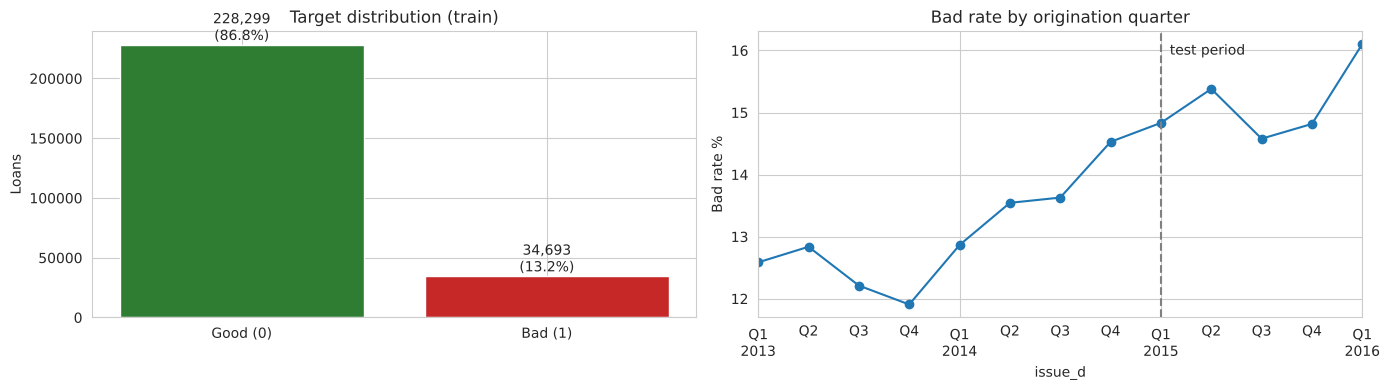

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

counts = y_train.value_counts().sort_index()
axes[0].bar(['Good (0)', 'Bad (1)'], counts.values, color=['#2E7D32', '#C62828'])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f'{v:,}\n({v / counts.sum():.1%})', ha='center', va='bottom')
axes[0].set_title('Target distribution (train)')
axes[0].set_ylabel('Loans')

quarterly = df[df['issue_d'] >= '2013-01-01'].groupby(df['issue_d'].dt.to_period('Q'))['target'].mean() * 100
quarterly.plot(ax=axes[1], marker='o')
axes[1].axvline(pd.Period('2015Q1', 'Q'), color='grey', ls='--')
axes[1].text(pd.Period('2015Q1', 'Q'), quarterly.max(), '  test period', va='top')
axes[1].set_title('Bad rate by origination quarter')
axes[1].set_ylabel('Bad rate %')

plt.tight_layout()
save('01_target_and_bad_rate')
plt.show()

### 7.2 Missing values

In [9]:
missing = (train[NUM_COLS + CAT_FEATS].isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
print('% missing (train):')
print(missing.round(2).to_string())

print('\nBad rate when missing vs present:')
for col in missing.index[:8]:
    miss_rate = train.loc[train[col].isna(), 'target'].mean()
    pres_rate = train.loc[train[col].notna(), 'target'].mean()
    print(f'{col:25s} missing: {miss_rate:.3f}   present: {pres_rate:.3f}')

% missing (train):
mths_since_last_delinq    51.80
mths_since_recent_inq     10.15
emp_length                 5.57
bc_util                    1.04
percent_bc_gt_75           1.01
bc_open_to_buy             0.97
mths_since_recent_bc       0.88
revol_util                 0.05
pct_tl_nvr_dlq             0.04
avg_cur_bal                0.00

Bad rate when missing vs present:
mths_since_last_delinq    missing: 0.130   present: 0.135
mths_since_recent_inq     missing: 0.097   present: 0.136
emp_length                missing: 0.194   present: 0.128
bc_util                   missing: 0.153   present: 0.132
percent_bc_gt_75          missing: 0.150   present: 0.132
bc_open_to_buy            missing: 0.152   present: 0.132
mths_since_recent_bc      missing: 0.150   present: 0.132
revol_util                missing: 0.128   present: 0.132


### 7.3 Distributions and skew

,count,mean,std,min,25%,50%,75%,max
annual_inc,262992.0,71943.94,55193.18,3000.0,43000.0,60000.0,86500.00,7500000.00
dti,262992.0,17.28,7.90,0.0,11.3,16.8,22.94,39.99
fico_range_low,262992.0,693.44,29.76,660.0,670.0,685.0,710.00,845.00
revol_util,262859.0,55.38,23.05,0.0,38.7,56.1,73.00,892.30
loan_amnt,262992.0,12616.86,7660.63,1000.0,7000.0,10000.0,16375.00,35000.00
acc_open_past_24mths,262992.0,4.18,2.78,0.0,2.0,4.0,6.00,53.00


Skewness:
annual_inc              29.93
dti                      0.22
fico_range_low           1.39
revol_util               0.02
loan_amnt                1.03
acc_open_past_24mths     1.17


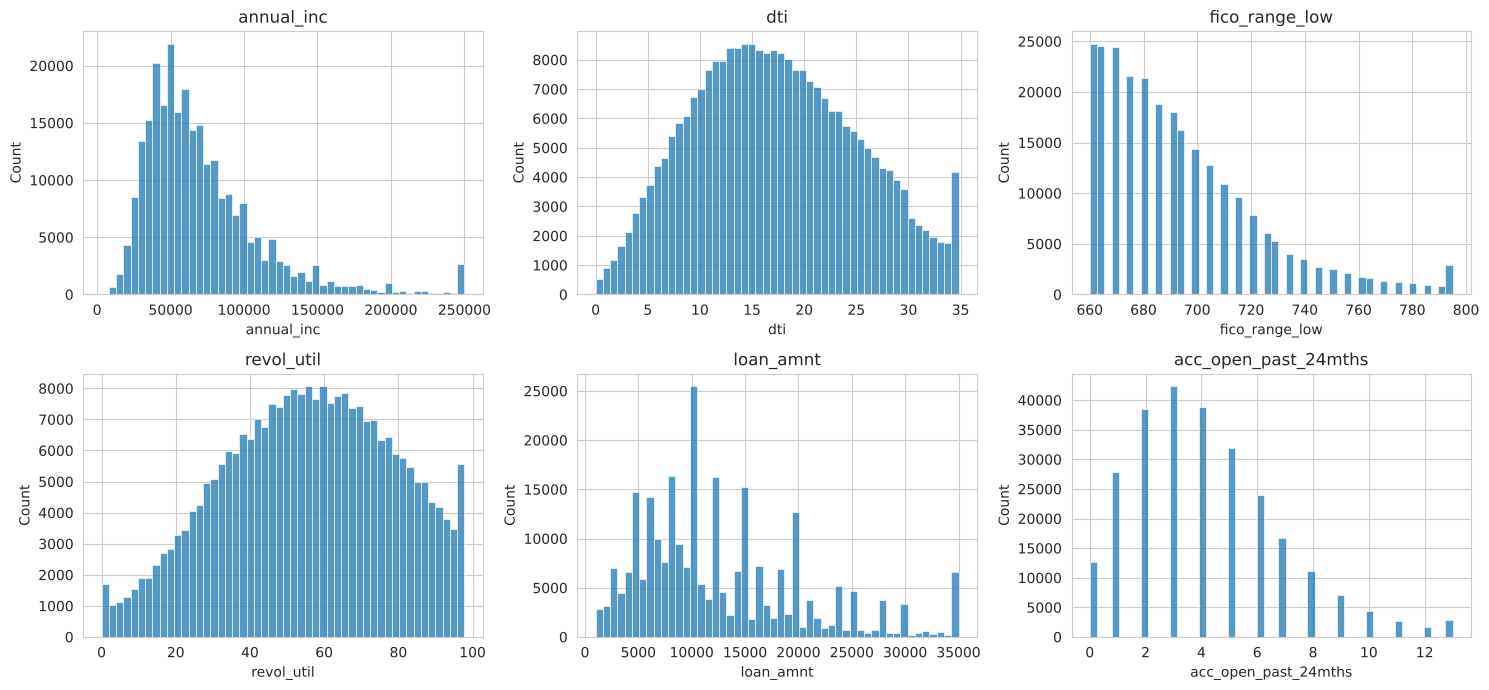

In [10]:
KEY_NUM = ['annual_inc', 'dti', 'fico_range_low', 'revol_util', 'loan_amnt', 'acc_open_past_24mths']

display(train[KEY_NUM].describe().T.round(2))
print('Skewness:')
print(train[KEY_NUM].skew().round(2).to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), KEY_NUM):
    clipped = train[col].clip(upper=train[col].quantile(0.99))   # clipped for display only
    sns.histplot(clipped.dropna(), bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 7.4 Bad rate by feature

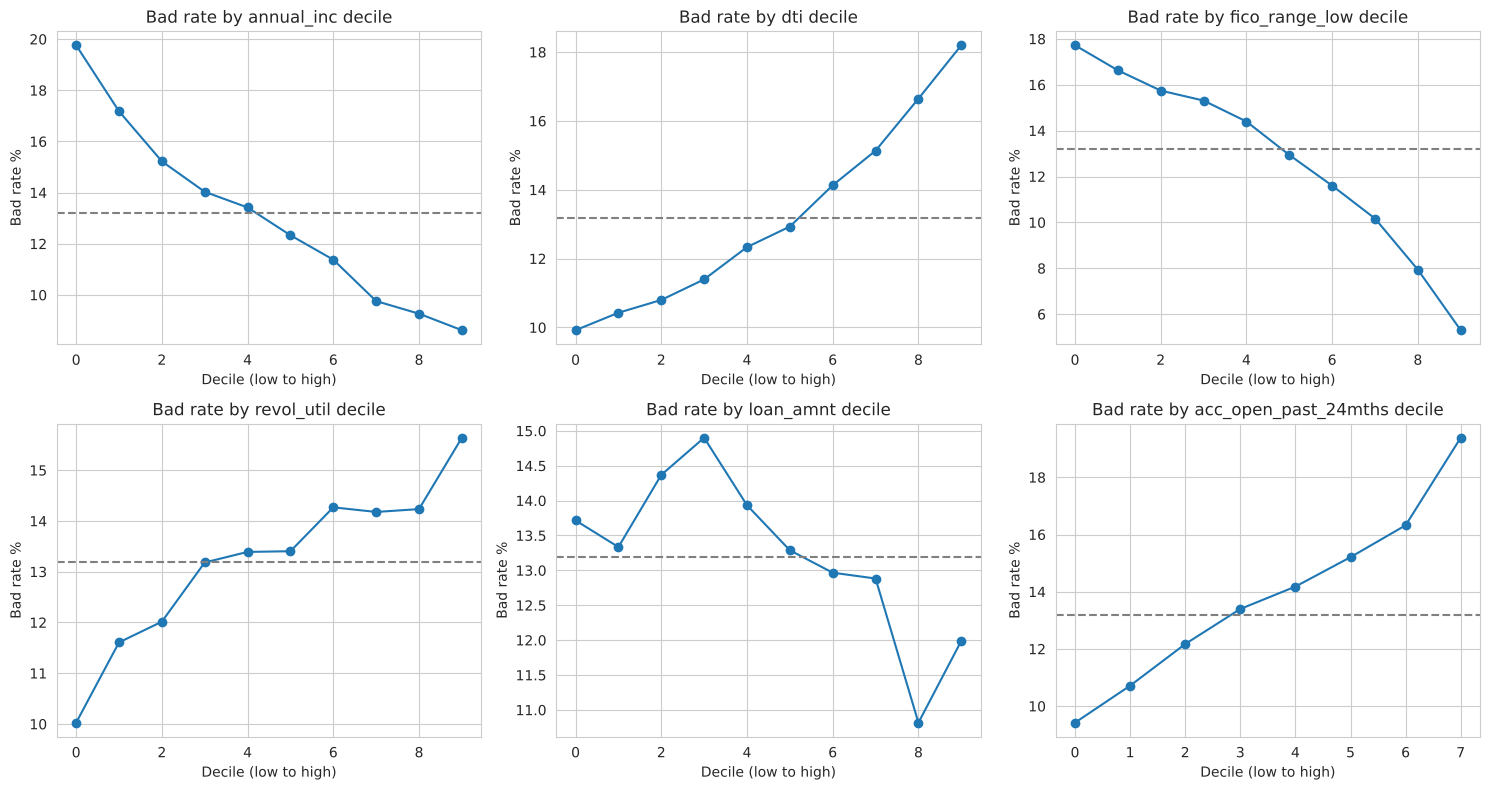

In [11]:
def bad_rate_by_bins(col, data, q=10):
    # Bad rate (%) in each decile of a numeric feature
    bins = pd.qcut(data[col], q=q, duplicates='drop')
    return data.groupby(bins, observed=True)['target'].mean() * 100

overall = y_train.mean() * 100
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), KEY_NUM):
    rate = bad_rate_by_bins(col, train)
    ax.plot(range(len(rate)), rate.values, marker='o')
    ax.axhline(overall, color='grey', ls='--')
    ax.set_title(f'Bad rate by {col} decile')
    ax.set_xlabel('Decile (low to high)')
    ax.set_ylabel('Bad rate %')
plt.tight_layout()
save('02_bad_rate_by_feature')
plt.show()

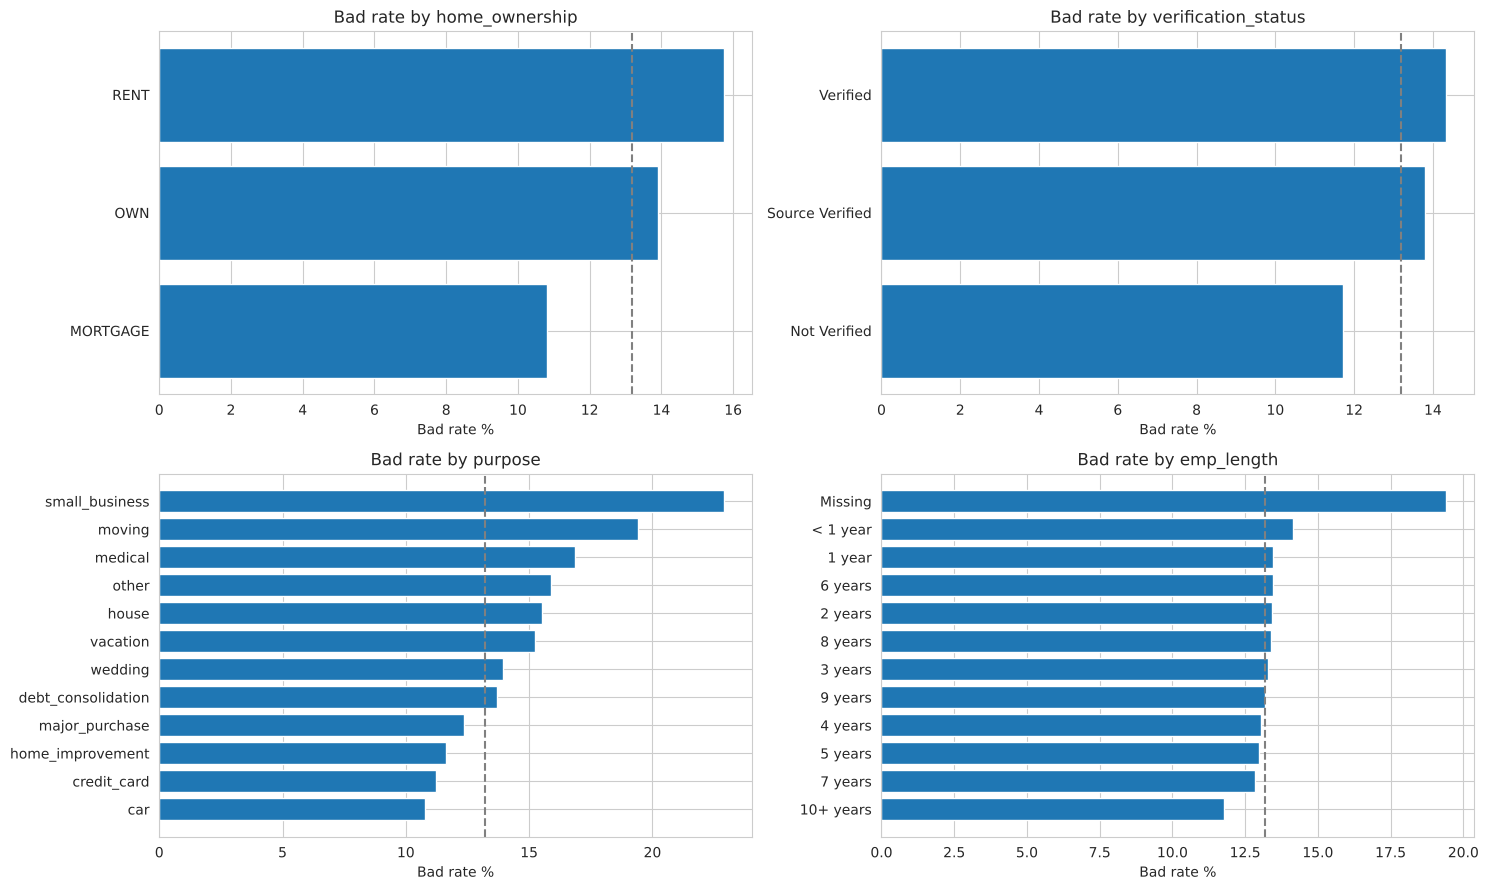

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.ravel(), CAT_FEATS):
    summary = train.groupby(train[col].fillna('Missing'))['target'].agg(['mean', 'size'])
    summary = summary[summary['size'] >= 500].sort_values('mean')   # ignore very small categories
    ax.barh(summary.index.astype(str), summary['mean'] * 100)
    ax.axvline(overall, color='grey', ls='--')
    ax.set_title(f'Bad rate by {col}')
    ax.set_xlabel('Bad rate %')
plt.tight_layout()
plt.show()

### 7.5 Correlation

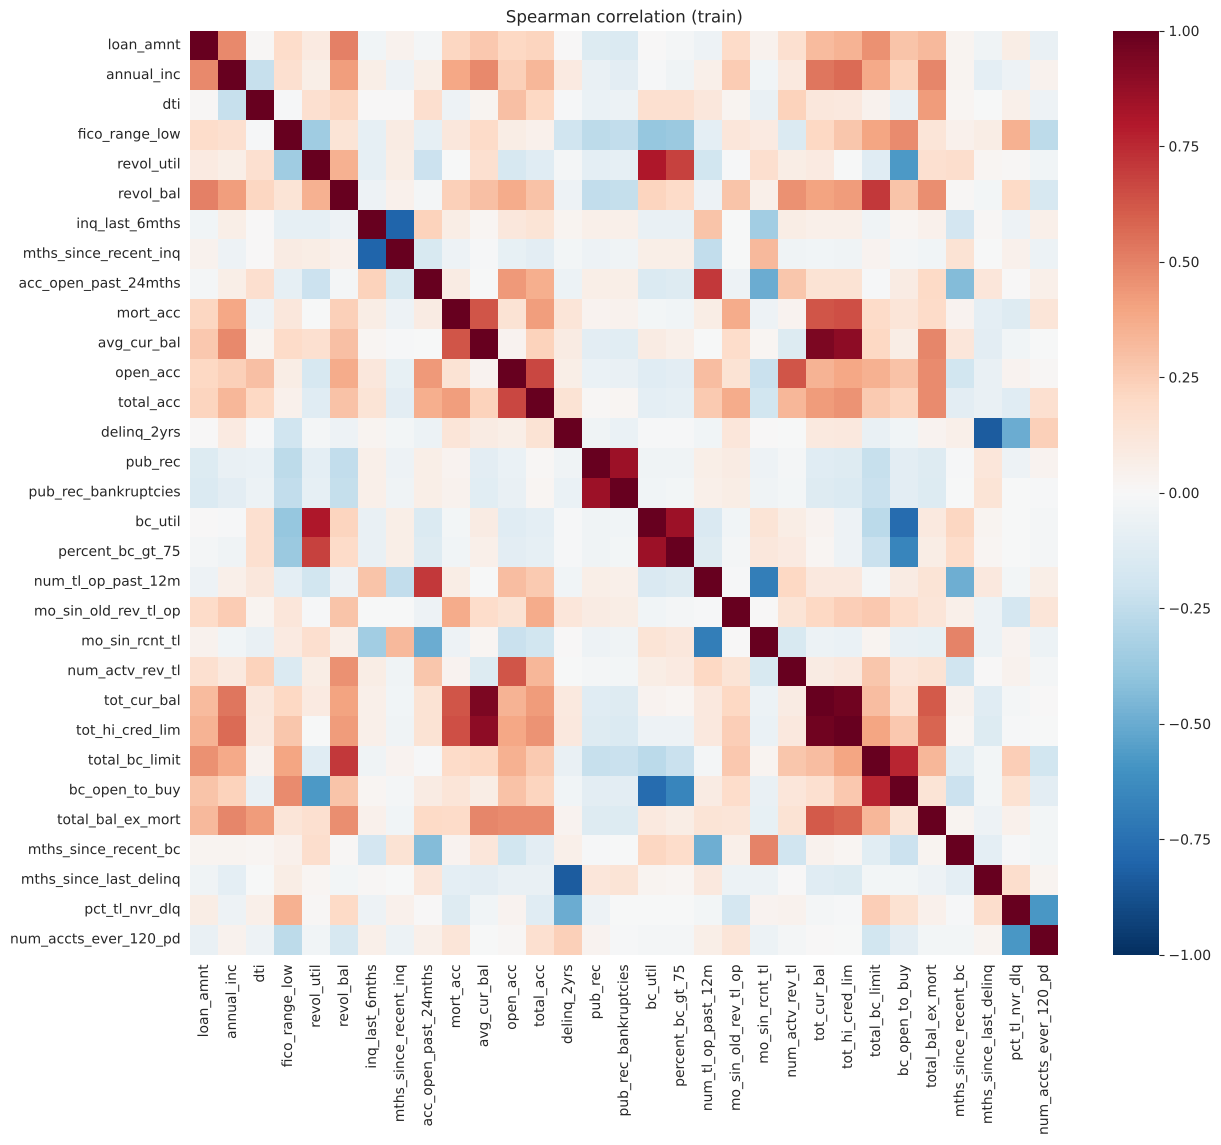

Pairs with |correlation| > 0.7:
tot_cur_bal           tot_hi_cred_lim           0.98
avg_cur_bal           tot_cur_bal               0.94
                      tot_hi_cred_lim           0.90
bc_util               percent_bc_gt_75          0.85
pub_rec               pub_rec_bankruptcies      0.85
revol_util            bc_util                   0.81
total_bc_limit        bc_open_to_buy            0.76
revol_bal             total_bc_limit            0.71
acc_open_past_24mths  num_tl_op_past_12m        0.71
bc_util               bc_open_to_buy           -0.77
inq_last_6mths        mths_since_recent_inq    -0.80
delinq_2yrs           mths_since_last_delinq   -0.83


In [13]:
corr = train[NUM_COLS].corr(method='spearman')   # rank correlation: robust to skew and outliers

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Spearman correlation (train)')
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print('Pairs with |correlation| > 0.7:')
print(upper[upper.abs() > 0.7].sort_values(ascending=False).round(2).to_string())

### 7.6 Outliers

In [14]:
print(train[['annual_inc', 'dti', 'revol_util', 'revol_bal', 'tot_cur_bal', 'loan_amnt']]
      .quantile([0.01, 0.25, 0.5, 0.75, 0.99, 1.0]).T.round(1))

                0.01     0.25     0.50      0.75      0.99       1.00
annual_inc   18000.0  43000.0  60000.0   86500.0  250000.0  7500000.0
dti              2.1     11.3     16.8      22.9      34.8       40.0
revol_util       3.8     38.7     56.1      73.0      97.8      892.3
revol_bal      508.9   6036.0  10810.0   18770.0   80964.1  2568995.0
tot_cur_bal   3154.9  24742.0  65124.5  192150.8  639083.4  4772549.0
loan_amnt     1600.0   7000.0  10000.0   16375.0   35000.0    35000.0


### EDA findings

- **Target:** the training bad rate is 13.2% (34,693 of 262,992 loans) and the test bad rate 15.2%. The bad rate rose from about 12% in late 2013 to 16% in Q1 2016, so PDs fitted on training data are expected to sit below observed test rates (addressed in section 17).
- **Missing values:** `mths_since_last_delinq` is missing for 52% of loans (no delinquency on record) with little difference in bad rate. Borrowers with no employment length default more often (19.4% against 12.8%) and those with no recent inquiry less often (9.7% against 13.6%). Missing values therefore form their own bin.
- **Skew and outliers:** annual income is highly skewed (skewness 29.9, maximum $7.5m) and revolving utilisation reaches 892%. Outliers are handled by binning; no values are capped.
- **Drivers:** bad rate falls steadily with FICO and income and rises with DTI and the number of recently opened accounts.
- **Correlation:** twelve pairs exceed |0.7|, mainly balance and limit fields (for example `tot_cur_bal` and `tot_hi_cred_lim` at 0.98). These are resolved in section 10.

## 8. Feature engineering

| Feature | Definition | Rationale |
|---|---|---|
| `credit_hist_months` | Months between the first credit line and the loan date | Longer credit history usually means lower risk |
| `loan_to_income` | Loan amount ÷ annual income | Size of the loan relative to the borrower's capacity |

Both are row-level calculations, so computing them on train and test separately introduces no leakage. Instalment-to-income was considered and rejected because the instalment is derived from LendingClub's interest rate (excluded in section 5).

37 candidate features


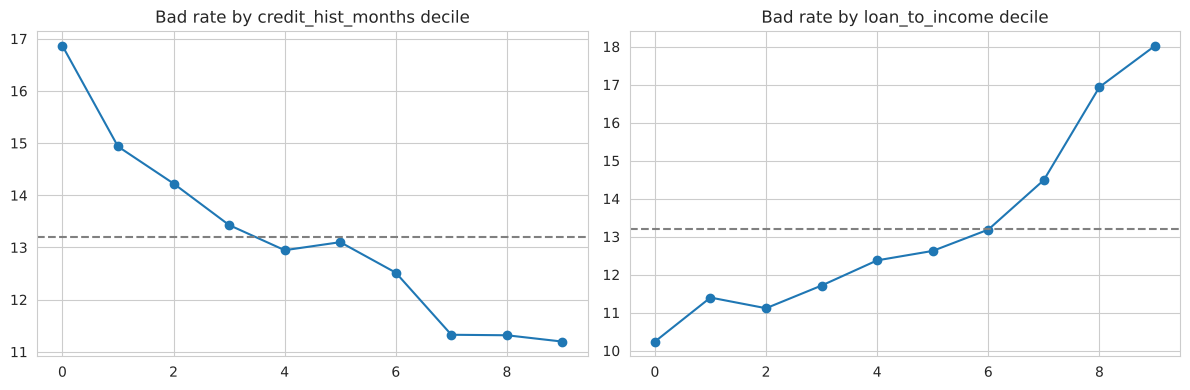

In [15]:
for data in (train, test):
    first_credit = pd.to_datetime(data['earliest_cr_line'], format='%b-%Y', errors='coerce')
    data['credit_hist_months'] = (data['issue_d'] - first_credit).dt.days / 30.44
    data['loan_to_income'] = data['loan_amnt'] / data['annual_inc'].replace(0, np.nan)

NUM_FEATS = NUM_COLS + ['credit_hist_months', 'loan_to_income']
ALL_FEATS = NUM_FEATS + CAT_FEATS
print(f'{len(ALL_FEATS)} candidate features')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['credit_hist_months', 'loan_to_income']):
    rate = bad_rate_by_bins(col, train)
    ax.plot(range(len(rate)), rate.values, marker='o')
    ax.axhline(overall, color='grey', ls='--')
    ax.set_title(f'Bad rate by {col} decile')
plt.tight_layout()
plt.show()

## 9. Binning, Weight of Evidence and Information Value

Each numeric feature is split into deciles (edges learned on train), and missing values form their own bin. Every bin is then replaced by its **Weight of Evidence**:

- WoE = ln( % of all goods in the bin ÷ % of all bads in the bin ), with 0.5 added to counts to avoid log(0)
- IV = Σ ( % goods − % bads ) × WoE

Positive WoE means safer than average. WoE handles outliers and missing values, puts every feature on the log-odds scale that logistic regression assumes, and makes each bin's effect explainable.

| IV | Predictive power |
|---|---|
| < 0.02 | Not useful |
| 0.02 to 0.1 | Weak |
| 0.1 to 0.3 | Medium |
| 0.3 to 0.5 | Strong |
| > 0.5 | Suspicious; check for leakage |

In [16]:
def make_bins(train_col, n_bins=10):
    # Decile edges from train; open outer edges so test values never fall outside
    _, edges = pd.qcut(train_col, q=n_bins, retbins=True, duplicates='drop')
    edges[0], edges[-1] = -np.inf, np.inf
    return edges

def bin_feature(series, edges):
    binned = pd.cut(series, bins=edges).astype(str)
    return binned.where(series.notna(), 'Missing')

def woe_table(binned, target):
    t = pd.DataFrame({'bin': binned.values, 'target': target.values})
    g = t.groupby('bin')['target'].agg(total='count', bad='sum')
    g['good'] = g['total'] - g['bad']
    g['good_pct'] = (g['good'] + 0.5) / (g['good'] + 0.5).sum()
    g['bad_pct'] = (g['bad'] + 0.5) / (g['bad'] + 0.5).sum()
    g['bad_rate'] = g['bad'] / g['total']
    g['woe'] = np.log(g['good_pct'] / g['bad_pct'])
    g['iv'] = (g['good_pct'] - g['bad_pct']) * g['woe']
    return g

bin_edges = {}
train_binned = pd.DataFrame(index=train.index)
test_binned = pd.DataFrame(index=test.index)

for col in NUM_FEATS:
    bin_edges[col] = make_bins(train[col])
    train_binned[col] = bin_feature(train[col], bin_edges[col])
    test_binned[col] = bin_feature(test[col], bin_edges[col])

for col in CAT_FEATS:
    train_binned[col] = train[col].fillna('Missing').astype(str)
    test_binned[col] = test[col].fillna('Missing').astype(str)

woe_maps, iv = {}, {}
for col in ALL_FEATS:
    tbl = woe_table(train_binned[col], y_train)
    woe_maps[col] = tbl['woe']
    iv[col] = tbl['iv'].sum()

iv = pd.Series(iv).sort_values(ascending=False)
print(iv.round(4).to_string())

fico_range_low            0.1330
annual_inc                0.0892
bc_open_to_buy            0.0782
tot_hi_cred_lim           0.0777
avg_cur_bal               0.0722
total_bc_limit            0.0719
tot_cur_bal               0.0639
acc_open_past_24mths      0.0566
dti                       0.0519
num_tl_op_past_12m        0.0458
home_ownership            0.0424
loan_to_income            0.0423
mort_acc                  0.0400
mo_sin_rcnt_tl            0.0372
percent_bc_gt_75          0.0354
mo_sin_old_rev_tl_op      0.0339
mths_since_recent_inq     0.0328
bc_util                   0.0296
mths_since_recent_bc      0.0289
purpose                   0.0217
credit_hist_months        0.0216
num_actv_rev_tl           0.0211
inq_last_6mths            0.0199
emp_length                0.0197
revol_bal                 0.0192
revol_util                0.0184
verification_status       0.0103
total_acc                 0.0098
loan_amnt                 0.0097
total_bal_ex_mort         0.0092
mths_since

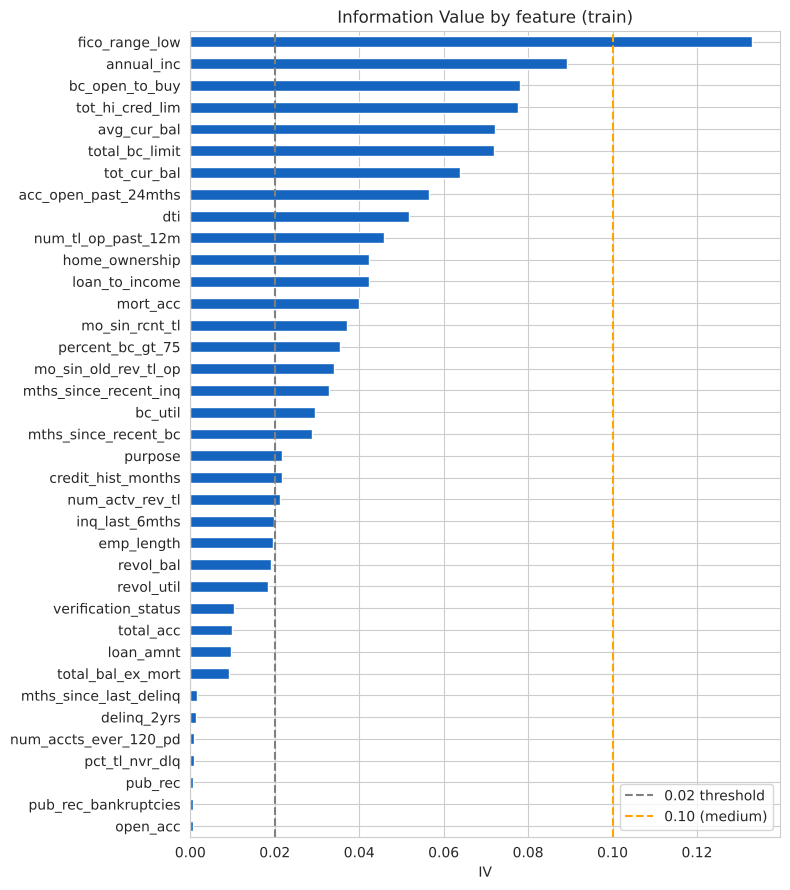

,total,bad_rate,woe,iv
bin,,,,
"(-inf, 665.0]",49307,0.1772,-0.3487,0.0259
"(665.0, 670.0]",24415,0.1663,-0.2720,0.0076
"(670.0, 675.0]",21543,0.1575,-0.2068,0.0038
"(675.0, 680.0]",21371,0.1531,-0.1737,0.0026
"(680.0, 685.0]",18843,0.1440,-0.1015,0.0008
"(685.0, 695.0]",34296,0.1294,0.0222,0.0001
"(695.0, 700.0]",14393,0.1160,0.1463,0.0011
"(700.0, 715.0]",33316,0.1017,0.2944,0.0098
"(715.0, 735.0]",23100,0.0794,0.5664,0.0228


In [17]:
plt.figure(figsize=(8, 9))
iv.sort_values().plot(kind='barh', color='#1565C0')
plt.axvline(0.02, color='grey', ls='--', label='0.02 threshold')
plt.axvline(0.10, color='orange', ls='--', label='0.10 (medium)')
plt.title('Information Value by feature (train)')
plt.xlabel('IV')
plt.legend()
plt.tight_layout()
save('03_information_value')
plt.show()

display(woe_table(train_binned['fico_range_low'], y_train)[['total', 'bad_rate', 'woe', 'iv']].round(4))

In [18]:
selected = iv[iv >= 0.02].index.tolist()
print(f'{len(selected)} features pass IV >= 0.02:')
print(selected)

def to_woe(binned_df, features):
    # Map each bin to its train WoE; bins unseen in train get 0 (neutral)
    return pd.DataFrame({c: binned_df[c].map(woe_maps[c]).astype(float).fillna(0)
                         for c in features}, index=binned_df.index)

X_train_woe = to_woe(train_binned, selected)
X_test_woe = to_woe(test_binned, selected)

22 features pass IV >= 0.02:
['fico_range_low', 'annual_inc', 'bc_open_to_buy', 'tot_hi_cred_lim', 'avg_cur_bal', 'total_bc_limit', 'tot_cur_bal', 'acc_open_past_24mths', 'dti', 'num_tl_op_past_12m', 'home_ownership', 'loan_to_income', 'mort_acc', 'mo_sin_rcnt_tl', 'percent_bc_gt_75', 'mo_sin_old_rev_tl_op', 'mths_since_recent_inq', 'bc_util', 'mths_since_recent_bc', 'purpose', 'credit_hist_months', 'num_actv_rev_tl']


**Findings.** 22 of 37 candidate features pass the IV threshold. FICO is the strongest (IV 0.133), followed by income (0.089) and the bureau balance and limit fields (0.06 to 0.08). No feature exceeds 0.5, consistent with the absence of leakage. FICO WoE rises monotonically from −0.35 in the lowest bin to +1.00 in the highest.

## 10. Multicollinearity and the logistic scorecard

When two features carry the same information, logistic coefficients become unstable and can change sign, which makes the scorecard impossible to explain.

1. **VIF** = 1 / (1 − R²), where R² comes from regressing a feature on all the others. The feature with the highest VIF is dropped until every VIF is ≤ 5.
2. **Sign and significance.** With WoE (high = safe) and target 1 = bad, every coefficient must be negative. Features with a positive coefficient or p-value above 0.05 are removed one at a time.

In [19]:
def vif_table(X):
    Xc = sm.add_constant(X)
    values = [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]
    return pd.Series(values, index=X.columns).sort_values(ascending=False)

features = selected.copy()
vif = vif_table(X_train_woe[features])
while vif.iloc[0] > 5:
    print(f'Dropping {vif.index[0]} (VIF = {vif.iloc[0]:.1f})')
    features.remove(vif.index[0])
    vif = vif_table(X_train_woe[features])

print('\nVIF after cleaning:')
print(vif.round(2).to_string())

Dropping tot_hi_cred_lim (VIF = 21.2)


Dropping bc_open_to_buy (VIF = 8.9)


Dropping tot_cur_bal (VIF = 7.2)



VIF after cleaning:
mo_sin_old_rev_tl_op     3.70
credit_hist_months       3.65
bc_util                  2.96
percent_bc_gt_75         2.77
avg_cur_bal              2.26
acc_open_past_24mths     2.19
num_tl_op_past_12m       2.18
annual_inc               1.90
total_bc_limit           1.84
mo_sin_rcnt_tl           1.79
home_ownership           1.78
mort_acc                 1.68
fico_range_low           1.61
num_actv_rev_tl          1.49
mths_since_recent_bc     1.45
loan_to_income           1.28
dti                      1.27
mths_since_recent_inq    1.20
purpose                  1.02


In [20]:
while True:
    logit_model = sm.Logit(y_train, sm.add_constant(X_train_woe[features])).fit(disp=0)
    coefs = logit_model.params.drop('const')
    pvals = logit_model.pvalues.drop('const')
    problems = coefs[(coefs > 0) | (pvals > 0.05)].index
    if len(problems) == 0:
        break
    worst = pvals[problems].idxmax()
    print(f'Dropping {worst}: coef = {coefs[worst]:.3f}, p = {pvals[worst]:.3f}')
    features.remove(worst)

print(logit_model.summary())
print(f'\nScorecard features: {len(features)}. All coefficients negative:',
      bool((logit_model.params.drop("const") < 0).all()))

Dropping credit_hist_months: coef = 0.449, p = 0.000


                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:               262992
Model:                          Logit   Df Residuals:                   262973
Method:                           MLE   Df Model:                           18
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                 0.05290
Time:                        18:23:30   Log-Likelihood:                -97145.
converged:                       True   LL-Null:                   -1.0257e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -1.8880      0.006   -312.223      0.000      -1.900      -1.876
fico_range_low           -0.5251      0.021    -24.723      0.000      -0.567      -0.483
annual_i

**Findings.** VIF removed `tot_hi_cred_lim`, `bc_open_to_buy` and `tot_cur_bal`, which duplicate other balance and limit fields. Backward elimination removed `credit_hist_months`, whose coefficient turned positive because it overlaps with the age of the oldest revolving account. The final scorecard has **18 features**, all with negative and significant coefficients and VIF below 4.

## 11. Baseline models

| Model | Input | Role |
|---|---|---|
| Logistic regression | WoE features | Champion candidate: interpretable, stable, standard for regulated scorecards |
| Decision tree | Raw features | Simple non-linear benchmark |
| Random forest | Raw features | Averaged trees, lower variance than a single tree |
| XGBoost | Raw features | Gradient boosting, usually strongest on tabular data. Challenger |

Tree models use raw features (missing values filled with the train median for the decision tree and random forest; XGBoost handles them natively).

**Metrics** (out-of-time test set): AUC; Gini = 2 × AUC − 1; KS (maximum gap between the cumulative bad and good distributions); PR-AUC; Brier score; mean PD against the actual bad rate; precision and recall at a 0.5 threshold.

In [21]:
def make_raw(data):
    X = data[NUM_FEATS].copy()
    dummies = pd.get_dummies(data[CAT_FEATS].fillna('Missing'), dtype=int)
    X = pd.concat([X, dummies], axis=1)
    X.columns = X.columns.str.replace(r'[^0-9a-zA-Z_]', '_', regex=True)   # XGBoost rejects < [ ]
    return X

X_train_raw = make_raw(train)
X_test_raw = make_raw(test).reindex(columns=X_train_raw.columns, fill_value=0)

medians = X_train_raw.median()          # learned on train only
X_train_imp = X_train_raw.fillna(medians)
X_test_imp = X_test_raw.fillna(medians)
print('Raw feature matrix:', X_train_raw.shape)

Raw feature matrix: (262992, 65)


In [22]:
def evaluate(name, y_true, p):
    y_true, p = np.asarray(y_true), np.asarray(p)
    auc = roc_auc_score(y_true, p)
    fpr, tpr, _ = roc_curve(y_true, p)
    y_pred = (p >= 0.5).astype(int)
    return {'model': name,
            'AUC': auc,
            'Gini': 2 * auc - 1,
            'KS': (tpr - fpr).max(),
            'PR-AUC': average_precision_score(y_true, p),
            'Brier': brier_score_loss(y_true, p),
            'Mean PD': p.mean(),
            'Actual bad rate': y_true.mean(),
            'Precision@0.5': precision_score(y_true, y_pred, zero_division=0),
            'Recall@0.5': recall_score(y_true, y_pred)}

results = []

p_test_logit = np.asarray(logit_model.predict(sm.add_constant(X_test_woe[features], has_constant='add')))
results.append(evaluate('Logistic regression (WoE)', y_test, p_test_logit))

dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=500, random_state=SEED)
dt.fit(X_train_imp, y_train)
results.append(evaluate('Decision tree', y_test, dt.predict_proba(X_test_imp)[:, 1]))

rf = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=200,
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train_imp, y_train)
results.append(evaluate('Random forest', y_test, rf.predict_proba(X_test_imp)[:, 1]))

xgb_base = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                         subsample=0.8, colsample_bytree=0.8, eval_metric='auc',
                         tree_method='hist', n_jobs=-1, random_state=SEED)
xgb_base.fit(X_train_raw, y_train)
p_test_xgb_base = xgb_base.predict_proba(X_test_raw)[:, 1]
results.append(evaluate('XGBoost (default)', y_test, p_test_xgb_base))

display(pd.DataFrame(results).set_index('model').round(4))

,AUC,Gini,KS,PR-AUC,Brier,Mean PD,Actual bad rate,Precision@0.5,Recall@0.5
model,,,,,,,,,
Logistic regression (WoE),0.6763,0.3526,0.2544,0.2600,0.1226,0.1333,0.1518,0.1429,0.0000
Decision tree,0.6399,0.2798,0.2038,0.2225,0.1251,0.1334,0.1518,0.0000,0.0000
Random forest,0.6772,0.3543,0.2557,0.2619,0.1236,0.1324,0.1518,0.0000,0.0000
XGBoost (default),0.6936,0.3872,0.2820,0.2786,0.1210,0.1376,0.1518,0.5655,0.0034


**Findings.** XGBoost leads (AUC 0.694), followed by the random forest (0.677) and the logistic scorecard (0.676). The single decision tree is weakest (0.640). Recall at a 0.5 threshold is close to zero for every model because almost no borrower has a PD above 50%; the decision threshold is set in section 15.

## 12. Class imbalance

The bad rate is around 14%, a mild imbalance. AUC, Gini and KS measure ranking and are not distorted by it. A PD model must also output **true probabilities**, because the PD feeds pricing, expected loss and capital.

The same logistic model is trained three ways: no adjustment, `class_weight='balanced'` and SMOTE oversampling (training data only).

In [23]:
imb_results = []
X_tr_f, X_te_f = X_train_woe[features], X_test_woe[features]

lr_plain = LogisticRegression(max_iter=1000).fit(X_tr_f, y_train)
imb_results.append(evaluate('No adjustment', y_test, lr_plain.predict_proba(X_te_f)[:, 1]))

lr_weighted = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_tr_f, y_train)
imb_results.append(evaluate("class_weight='balanced'", y_test, lr_weighted.predict_proba(X_te_f)[:, 1]))

X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X_tr_f, y_train)
lr_smote = LogisticRegression(max_iter=1000).fit(X_smote, y_smote)
imb_results.append(evaluate('SMOTE', y_test, lr_smote.predict_proba(X_te_f)[:, 1]))

display(pd.DataFrame(imb_results).set_index('model')
        [['Gini', 'KS', 'Brier', 'Mean PD', 'Actual bad rate', 'Precision@0.5', 'Recall@0.5']].round(4))

,Gini,KS,Brier,Mean PD,Actual bad rate,Precision@0.5,Recall@0.5
model,,,,,,,
No adjustment,0.3525,0.2545,0.1226,0.1334,0.1518,0.2000,0.0001
class_weight='balanced',0.3521,0.2542,0.2285,0.4688,0.1518,0.2259,0.6565
SMOTE,0.3511,0.2527,0.2275,0.4657,0.1518,0.2261,0.6507


**Findings.** Rebalancing leaves ranking unchanged (Gini 0.353, 0.352 and 0.351) but raises the mean PD from 13.3% to about 47% against an actual bad rate of 15.2%, and the Brier score worsens from 0.123 to 0.228. The higher recall at 0.5 comes from inflated probabilities rather than better discrimination. The natural class balance is kept and imbalance is handled through the cut-off.

## 13. Hyperparameter tuning and time-based cross-validation

Standard K-fold mixes years, so a model can be validated on loans older than its training loans. `TimeSeriesSplit` always validates on **later** loans, consistent with the out-of-time design (training data is sorted by issue date). The test set is not used for tuning.

- **Logistic regression:** grid search over `C`, the inverse of regularisation strength
- **XGBoost:** randomised search over depth, learning rate, number of trees, minimum child weight, row and column sampling and L2 regularisation

In [24]:
tscv = TimeSeriesSplit(n_splits=4)

lr_search = GridSearchCV(LogisticRegression(max_iter=1000),
                         param_grid={'C': [0.001, 0.01, 0.1, 1, 10]},
                         cv=tscv, scoring='roc_auc', n_jobs=-1)
lr_search.fit(X_train_woe[features], y_train)

print('Best C:', lr_search.best_params_['C'], '| mean CV AUC:', round(lr_search.best_score_, 4))
display(pd.DataFrame(lr_search.cv_results_)[['param_C', 'mean_test_score', 'std_test_score']].round(4))

Best C: 0.1 | mean CV AUC: 0.6655


,param_C,mean_test_score,std_test_score
0,0.001,0.6605,0.0056
1,0.010,0.6650,0.0055
2,0.100,0.6655,0.0053
3,1.000,0.6655,0.0053
4,10.000,0.6655,0.0053


In [25]:
param_dist = {'max_depth': [2, 3, 4, 5, 6],
              'learning_rate': [0.01, 0.03, 0.05, 0.1],
              'n_estimators': [200, 400, 600],
              'min_child_weight': [1, 5, 10, 50],
              'subsample': [0.7, 0.8, 1.0],
              'colsample_bytree': [0.6, 0.8, 1.0],
              'reg_lambda': [1, 5, 10]}

xgb_search = RandomizedSearchCV(
    XGBClassifier(eval_metric='auc', tree_method='hist', n_jobs=-1, random_state=SEED),
    param_distributions=param_dist, n_iter=15, cv=tscv, scoring='roc_auc',
    random_state=SEED, verbose=1)
xgb_search.fit(X_train_raw, y_train)

best_xgb = xgb_search.best_estimator_
print('Best parameters:', xgb_search.best_params_)
print('Mean CV AUC:', round(xgb_search.best_score_, 4))

Fitting 4 folds for each of 15 candidates, totalling 60 fits


Best parameters: {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Mean CV AUC: 0.68


In [26]:
# AUC in each time-based fold for the best settings of each model
def fold_scores(search):
    i = search.best_index_
    return [search.cv_results_[f'split{k}_test_score'][i] for k in range(tscv.n_splits)]

cv_table = pd.DataFrame({'Logistic (WoE)': fold_scores(lr_search),
                         'XGBoost (tuned)': fold_scores(xgb_search)},
                        index=[f'Fold {k + 1}' for k in range(tscv.n_splits)])
cv_table.loc['Mean'] = cv_table.mean()
cv_table.loc['Std'] = cv_table.iloc[:-1].std()
display(cv_table.round(4))

,Logistic (WoE),XGBoost (tuned)
Fold 1,0.6609,0.6742
Fold 2,0.6610,0.6750
Fold 3,0.6739,0.6860
Fold 4,0.6661,0.6849
Mean,0.6655,0.6800
Std,0.0061,0.0063


**Findings.** Every value of C from 0.01 to 10 gives the same cross-validated AUC (0.665): with 18 WoE features and 263,000 loans the scorecard has little room to overfit. The best XGBoost (depth 5, learning rate 0.03, 400 trees, L2 penalty 10) reaches a cross-validated AUC of 0.680. Fold-to-fold variation is small for both models (standard deviation about 0.006) and XGBoost leads in every fold.

## 14. Final model comparison

All models are scored once on the out-of-time test set. A **bootstrap** (200 resamples of the test set) gives a 95% interval for the AUC difference between tuned XGBoost and the logistic scorecard; an interval excluding zero means the gap is not noise.

,AUC,Gini,KS,PR-AUC,Brier,Mean PD,Actual bad rate,Precision@0.5,Recall@0.5
model,,,,,,,,,
Logistic regression (WoE),0.6763,0.3526,0.2544,0.2600,0.1226,0.1333,0.1518,0.1429,0.0000
Decision tree,0.6399,0.2798,0.2038,0.2225,0.1251,0.1334,0.1518,0.0000,0.0000
Random forest,0.6772,0.3543,0.2557,0.2619,0.1236,0.1324,0.1518,0.0000,0.0000
XGBoost (default),0.6936,0.3872,0.2820,0.2786,0.1210,0.1376,0.1518,0.5655,0.0034
"Logistic regression (WoE, tuned C)",0.6762,0.3525,0.2545,0.2600,0.1226,0.1334,0.1518,0.2000,0.0000
XGBoost (tuned),0.6948,0.3896,0.2827,0.2799,0.1209,0.1372,0.1518,0.5816,0.0025


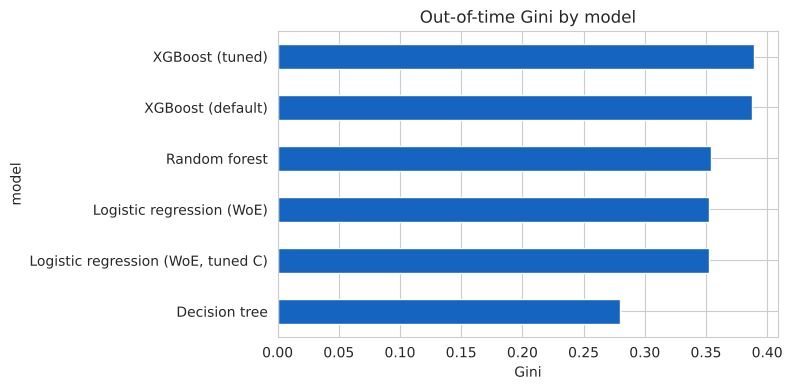

In [27]:
p_test_lr_tuned = lr_search.best_estimator_.predict_proba(X_test_woe[features])[:, 1]
p_test_xgb = best_xgb.predict_proba(X_test_raw)[:, 1]

results.append(evaluate('Logistic regression (WoE, tuned C)', y_test, p_test_lr_tuned))
results.append(evaluate('XGBoost (tuned)', y_test, p_test_xgb))

results_df = pd.DataFrame(results).set_index('model').round(4)
display(results_df)

results_df['Gini'].sort_values().plot(kind='barh', figsize=(8, 4), color='#1565C0')
plt.title('Out-of-time Gini by model')
plt.xlabel('Gini')
plt.tight_layout()
save('04_gini_by_model')
plt.show()

AUC gap (XGBoost minus logistic): mean 0.0185, 95% CI [0.0174, 0.0197]


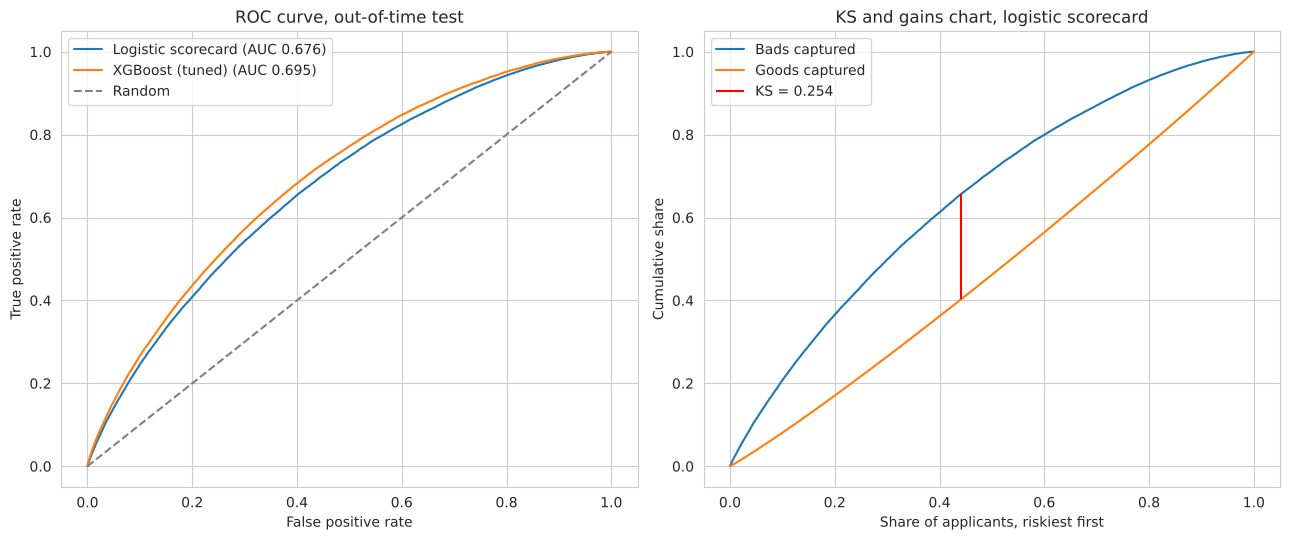

In [28]:
rng = np.random.default_rng(SEED)
yv = y_test.values

gaps = []
for _ in range(200):
    idx = rng.integers(0, len(yv), len(yv))
    gaps.append(roc_auc_score(yv[idx], p_test_xgb[idx]) - roc_auc_score(yv[idx], p_test_logit[idx]))
low, high = np.percentile(gaps, [2.5, 97.5])
print(f'AUC gap (XGBoost minus logistic): mean {np.mean(gaps):.4f}, 95% CI [{low:.4f}, {high:.4f}]')

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# ROC curves
for name, p in [('Logistic scorecard', p_test_logit), ('XGBoost (tuned)', p_test_xgb)]:
    fpr, tpr, _ = roc_curve(yv, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(yv, p):.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='grey', label='Random')
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curve, out-of-time test')
axes[0].legend()

# KS chart for the scorecard: cumulative share of bads and goods, riskiest borrowers first
order = np.argsort(-p_test_logit)
cum_bad = np.cumsum(yv[order]) / yv.sum()
cum_good = np.cumsum(1 - yv[order]) / (1 - yv).sum()
population = np.arange(1, len(yv) + 1) / len(yv)
ks_idx = np.argmax(cum_bad - cum_good)
axes[1].plot(population, cum_bad, label='Bads captured')
axes[1].plot(population, cum_good, label='Goods captured')
axes[1].vlines(population[ks_idx], cum_good[ks_idx], cum_bad[ks_idx], color='red',
               label=f'KS = {cum_bad[ks_idx] - cum_good[ks_idx]:.3f}')
axes[1].set_xlabel('Share of applicants, riskiest first')
axes[1].set_ylabel('Cumulative share')
axes[1].set_title('KS and gains chart, logistic scorecard')
axes[1].legend()

plt.tight_layout()
save('05_roc_and_ks')
plt.show()

**Champion selection.** Tuning moved XGBoost from 0.694 to 0.695 AUC on test and left the scorecard unchanged at 0.676. XGBoost leads by 0.019 AUC (95% CI 0.017 to 0.020), a real but small gain of 3.7 Gini points. The **WoE logistic scorecard is the champion** because its drivers are monotonic and explainable, it converts directly into scorecard points and decline reasons, and it is stable over time. XGBoost is retained as a challenger for ongoing monitoring.

## 15. Cut-off selection

Almost no borrower has a PD above 50%, so a 0.5 threshold approves nearly everyone. The cut-off is set from the relative cost of each error:

- **False negative** (approve a borrower who defaults): loss of most of the outstanding principal
- **False positive** (decline a borrower who would repay): loss of interest income

**Assumption:** a missed default costs five times as much as a wrongly declined good borrower (`COST_FN = 5`, `COST_FP = 1`). The threshold minimising total cost is chosen on **train** and applied to test. Positive class = bad.

Cost-minimising threshold (from train): 0.16


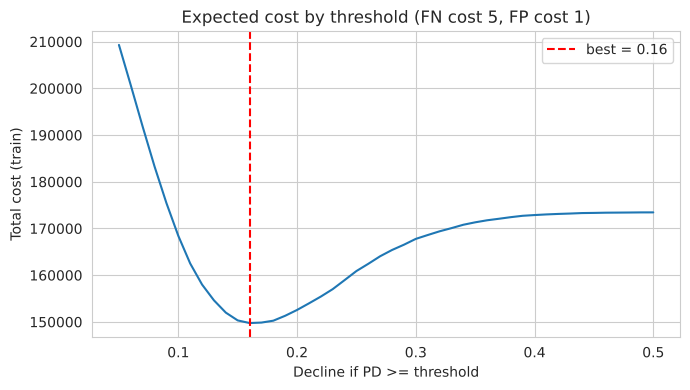

In [29]:
p_train_logit = np.asarray(logit_model.predict(sm.add_constant(X_train_woe[features])))

COST_FN, COST_FP = 5, 1
thresholds = np.arange(0.05, 0.51, 0.01)
costs = [COST_FN * ((p_train_logit < t) & (y_train == 1)).sum() +
         COST_FP * ((p_train_logit >= t) & (y_train == 0)).sum() for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]
print(f'Cost-minimising threshold (from train): {best_t:.2f}')

plt.figure(figsize=(7, 4))
plt.plot(thresholds, costs)
plt.axvline(best_t, color='red', ls='--', label=f'best = {best_t:.2f}')
plt.xlabel('Decline if PD >= threshold')
plt.ylabel('Total cost (train)')
plt.title(f'Expected cost by threshold (FN cost {COST_FN}, FP cost {COST_FP})')
plt.legend()
plt.tight_layout()
plt.show()

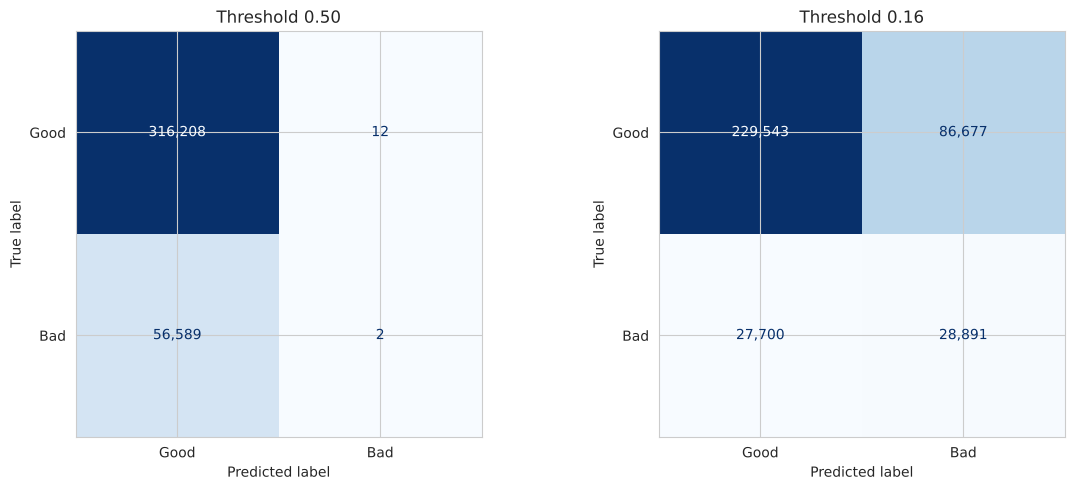

Classification report at threshold 0.16 (test):
                precision    recall  f1-score   support

Good (approve)       0.89      0.73      0.80    316220
 Bad (decline)       0.25      0.51      0.34     56591

      accuracy                           0.69    372811
     macro avg       0.57      0.62      0.57    372811
  weighted avg       0.79      0.69      0.73    372811



In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, t in zip(axes, [0.5, best_t]):
    y_pred = (p_test_logit >= t).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=['Good', 'Bad']).plot(ax=ax, cmap='Blues',
                                                                values_format=',', colorbar=False)
    ax.set_title(f'Threshold {t:.2f}')
plt.tight_layout()
save('06_confusion_matrices')
plt.show()

print(f'Classification report at threshold {best_t:.2f} (test):')
print(classification_report(y_test, (p_test_logit >= best_t).astype(int),
                            target_names=['Good (approve)', 'Bad (decline)']))

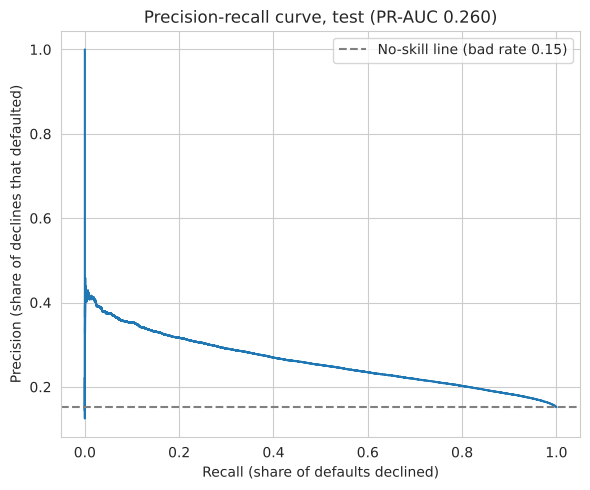

,Approval rate,Bad rate of approved,Defaults avoided
0,50%,8.71%,71.3%
1,60%,9.81%,61.2%
2,70%,10.88%,49.8%
3,80%,12.04%,36.5%
4,90%,13.37%,20.7%
5,100%,15.18%,0.0%


In [31]:
precision, recall, _ = precision_recall_curve(y_test, p_test_logit)
plt.figure(figsize=(6, 5))
plt.plot(recall, precision)
plt.axhline(y_test.mean(), color='grey', ls='--', label=f'No-skill line (bad rate {y_test.mean():.2f})')
plt.xlabel('Recall (share of defaults declined)')
plt.ylabel('Precision (share of declines that defaulted)')
plt.title(f'Precision-recall curve, test (PR-AUC {average_precision_score(y_test, p_test_logit):.3f})')
plt.legend()
plt.tight_layout()
plt.show()

rows = []
for approve in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    cutoff = np.quantile(p_test_logit, approve)
    approved = p_test_logit <= cutoff
    rows.append({'Approval rate': f'{approve:.0%}',
                 'Bad rate of approved': f'{y_test[approved].mean():.2%}',
                 'Defaults avoided': f'{1 - y_test[approved].sum() / y_test.sum():.1%}'})
approval_table = pd.DataFrame(rows)
display(approval_table)

**Findings.** At the cost-based threshold of 0.16 the scorecard declines 51% of eventual defaulters, and 25% of declined applicants default, against a base rate of 15.2%. At 0.5 it declines almost nobody. Approving the safest 70% of applicants lowers the bad rate of the approved book from 15.2% to 10.9% and avoids 49.8% of defaults.

## 16. Calibration and stability

- **Calibration:** predicted against observed bad rate by PD decile
- **Stability:** Gini and KS for each test sub-period
- **PSI** (Population Stability Index) on the score and **CSI** on each feature: Σ (actual% − expected%) × ln(actual% ÷ expected%). Below 0.1 is stable, 0.1 to 0.25 needs monitoring, above 0.25 needs investigation.

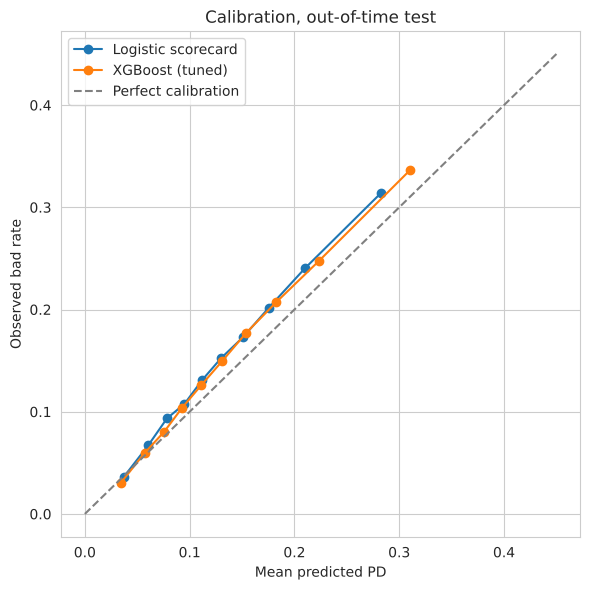

,predicted,observed,loans
decile,,,
0,3.73,3.63,37282
1,6.05,6.71,37281
2,7.83,9.34,37281
3,9.50,10.76,37281
4,11.21,13.12,37281
5,13.03,15.27,37281
6,15.09,17.29,37281
7,17.57,20.19,37281
8,21.00,24.03,37281


In [32]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in [('Logistic scorecard', p_test_logit), ('XGBoost (tuned)', p_test_xgb)]:
    frac_bad, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac_bad, marker='o', label=name)
ax.plot([0, 0.45], [0, 0.45], '--', color='grey', label='Perfect calibration')
ax.set_xlabel('Mean predicted PD')
ax.set_ylabel('Observed bad rate')
ax.set_title('Calibration, out-of-time test')
ax.legend()
plt.tight_layout()
plt.show()

cal = pd.DataFrame({'pd': p_test_logit, 'bad': y_test.values})
cal['decile'] = pd.qcut(cal['pd'], 10, labels=False, duplicates='drop')
display((cal.groupby('decile').agg(predicted=('pd', 'mean'), observed=('bad', 'mean'), loans=('bad', 'size'))
         .assign(predicted=lambda d: (d['predicted'] * 100).round(2),
                 observed=lambda d: (d['observed'] * 100).round(2))))

In [33]:
test_eval = test[['issue_d', 'target']].copy()
test_eval['pd'] = p_test_logit
test_eval['period'] = np.select([test_eval['issue_d'] < '2015-07-01',
                                 test_eval['issue_d'] < '2016-01-01'],
                                ['2015H1', '2015H2'], default='2016Q1')

print('Stability by test period:')
for period, g in test_eval.groupby('period'):
    r = evaluate(period, g['target'], g['pd'])
    print(f"  {period}: n={len(g):,}  bad rate={g['target'].mean():.3f}  Gini={r['Gini']:.3f}  KS={r['KS']:.3f}")

def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return np.sum((a - e) * np.log(a / e))

def csi(train_bins, test_bins):
    e = train_bins.value_counts(normalize=True)
    a = test_bins.value_counts(normalize=True)
    e, a = e.align(a, fill_value=0)
    e, a = e.clip(lower=1e-4), a.clip(lower=1e-4)
    return ((a - e) * np.log(a / e)).sum()

print(f'\nScore PSI (train vs test): {psi(p_train_logit, p_test_logit):.4f}')
print('\nCSI per scorecard feature:')
print(pd.Series({c: csi(train_binned[c], test_binned[c]) for c in features})
      .sort_values(ascending=False).round(4).to_string())

Stability by test period:
  2015H1: n=120,790  bad rate=0.151  Gini=0.341  KS=0.248


  2015H2: n=162,236  bad rate=0.147  Gini=0.354  KS=0.255
  2016Q1: n=89,785  bad rate=0.161  Gini=0.367  KS=0.263

Score PSI (train vs test): 0.0021

CSI per scorecard feature:


percent_bc_gt_75         0.0319
num_tl_op_past_12m       0.0295
dti                      0.0283
bc_util                  0.0253
acc_open_past_24mths     0.0232
mo_sin_old_rev_tl_op     0.0130
num_actv_rev_tl          0.0115
total_bc_limit           0.0095
purpose                  0.0086
mort_acc                 0.0081
mo_sin_rcnt_tl           0.0051
avg_cur_bal              0.0050
home_ownership           0.0045
annual_inc               0.0044
loan_to_income           0.0043
mths_since_recent_bc     0.0043
mths_since_recent_inq    0.0034
fico_range_low           0.0030


**Findings.** The model ranks borrowers correctly across all ten deciles but under-predicts by 1 to 3 percentage points from the second decile upwards, because the test bad rate (15.2%) is higher than the training bad rate (13.2%). This base-rate drift is corrected in section 17. Gini is stable and improves slightly across test periods (0.341, 0.354, 0.367). Score PSI is 0.002 and every feature CSI is below 0.04, so the applicant population is stable.

## 17. Recalibration

When the portfolio bad rate moves, a model can keep ranking well while its PDs drift. Lenders first correct the PD level without retraining:

| Method | Description | Ranking |
|---|---|---|
| Intercept shift | Adds one constant to every log-odds: shift = log-odds(recent bad rate) − log-odds(mean model PD) | Unchanged |
| Platt scaling | Logistic regression of the outcome on the model's log-odds (slope and intercept) | Unchanged |
| Isotonic regression | Monotonic step function from PD to observed bad rate | Ties can change AUC slightly |

Calibrators are fitted on Jan to Jun 2015 and evaluated on Jul 2015 to Mar 2016. In production, recalibration would use the latest vintages with sufficient history or an early-default definition (for example 90+ days past due within 12 months).

In [34]:
y_arr = y_test.values
calib_mask = (test['issue_d'] < '2015-07-01').values   # fit period
eval_mask = ~calib_mask                                 # evaluation period

recent_bad_rate = y_arr[calib_mask].mean()
shift = log_odds(recent_bad_rate) - log_odds(p_test_logit[calib_mask].mean())
p_shift = expit(log_odds(p_test_logit) + shift)
print(f'Recent bad rate {recent_bad_rate:.2%}, mean model PD {p_test_logit[calib_mask].mean():.2%}, '
      f'shift {shift:+.3f}')

platt = LogisticRegression(C=1e6)   # large C: effectively unregularised
platt.fit(log_odds(p_test_logit[calib_mask]).reshape(-1, 1), y_arr[calib_mask])
p_platt = platt.predict_proba(log_odds(p_test_logit).reshape(-1, 1))[:, 1]

iso = IsotonicRegression(out_of_bounds='clip')
iso.fit(p_test_logit[calib_mask], y_arr[calib_mask])
p_iso = iso.predict(p_test_logit)

calibrated = {'No recalibration': p_test_logit, 'Intercept shift': p_shift,
              'Platt scaling': p_platt, 'Isotonic': p_iso}

rows = []
for name, p in calibrated.items():
    pe, ye = p[eval_mask], y_arr[eval_mask]
    rows.append({'method': name, 'mean PD': pe.mean(), 'actual bad rate': ye.mean(),
                 'Brier': brier_score_loss(ye, pe), 'AUC': roc_auc_score(ye, pe)})
display(pd.DataFrame(rows).set_index('method').round(4))

Recent bad rate 15.12%, mean model PD 13.80%, shift +0.108


,mean PD,actual bad rate,Brier,AUC
method,,,,
No recalibration,0.1311,0.1521,0.1227,0.6792
Intercept shift,0.1432,0.1521,0.1222,0.6792
Platt scaling,0.1438,0.1521,0.1222,0.6792
Isotonic,0.1438,0.1521,0.1222,0.6790


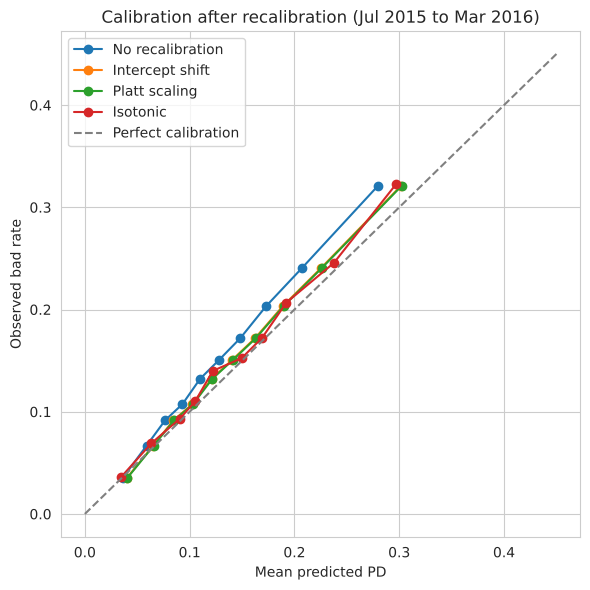

In [35]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in calibrated.items():
    frac_bad, mean_pred = calibration_curve(y_arr[eval_mask], p[eval_mask], n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac_bad, marker='o', label=name)
ax.plot([0, 0.45], [0, 0.45], '--', color='grey', label='Perfect calibration')
ax.set_xlabel('Mean predicted PD')
ax.set_ylabel('Observed bad rate')
ax.set_title('Calibration after recalibration (Jul 2015 to Mar 2016)')
ax.legend()
plt.tight_layout()
save('07_calibration')
plt.show()

p_test_cal = p_shift   # intercept shift carried forward: ranking and scorecard points unchanged

**Findings.** The intercept shift (+0.108 on the log-odds scale) raises the mean PD in the evaluation period from 13.1% to 14.3% and lowers the Brier score from 0.1227 to 0.1222 without changing AUC. Platt scaling and isotonic regression reach the same Brier score, so the intercept shift is preferred as the simplest adjustment. The remaining gap to the 15.2% actual rate reflects a further rise in defaults after the fitting period, which supports regular recalibration in production.

## 18. Explainability

- **Logistic scorecard:** each coefficient scales a feature's WoE. All coefficients are negative, so a riskier bin always increases the PD, and every decline can be explained by the bins that cost the most points.
- **XGBoost:** SHAP values give each feature's contribution to each prediction.

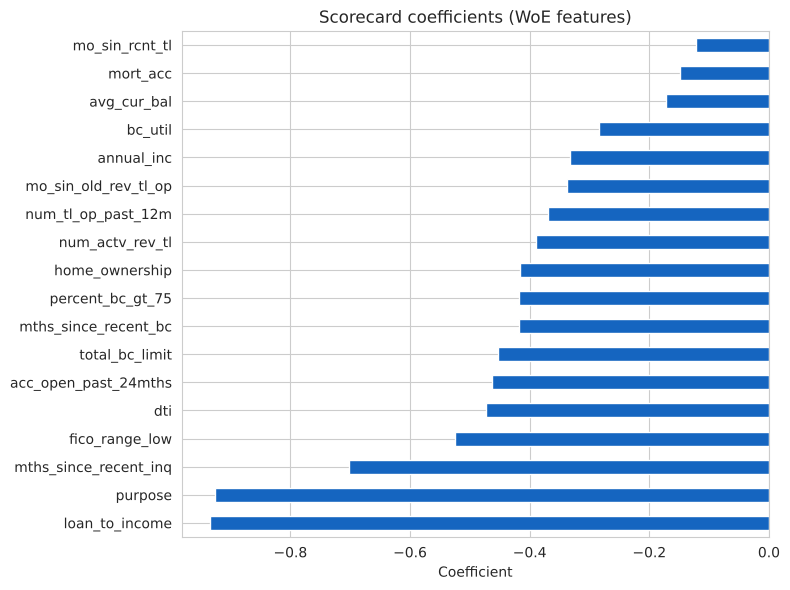

In [36]:
coefs = logit_model.params.drop('const').sort_values()
plt.figure(figsize=(8, 6))
coefs.plot(kind='barh', color='#1565C0')
plt.title('Scorecard coefficients (WoE features)')
plt.xlabel('Coefficient')
plt.tight_layout()
plt.show()

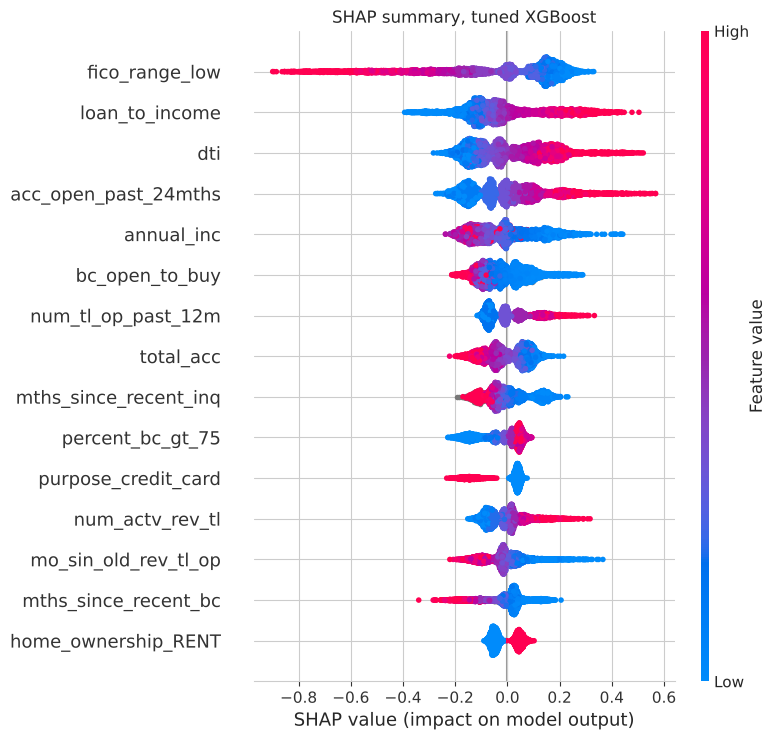

In [37]:
import shap

sample = X_test_raw.sample(5000, random_state=SEED)
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(sample)
shap.summary_plot(shap_values, sample, max_display=15, show=False)
plt.title('SHAP summary, tuned XGBoost')
plt.tight_layout()
save('08_shap_summary')
plt.show()

**Findings.** Both models rely on the same drivers: FICO, loan-to-income, DTI, recently opened accounts and income. Higher FICO and income lower the PD; higher loan-to-income, DTI and recent account openings raise it. Agreement between two very different model types supports the scorecard's drivers.

## 19. Scorecard points

The logistic model is converted into points using the standard scaling:

- **PDO** (points to double the odds) = 20; base score 600 at good:bad odds of 50:1
- Factor = PDO ÷ ln 2; Offset = 600 − Factor × ln 50
- Score = Offset − Factor × ln(PD ÷ (1 − PD))
- Points for a bin = −(coefficient × WoE + intercept ÷ n) × Factor + Offset ÷ n, where n is the number of features

Higher score means lower risk. The full points table is saved to `artefacts/scorecard_points.csv`.

,feature,bin,woe,points
0,fico_range_low,"(-inf, 665.0]",-0.349,25
1,fico_range_low,"(665.0, 670.0]",-0.272,26
2,fico_range_low,"(670.0, 675.0]",-0.207,27
3,fico_range_low,"(675.0, 680.0]",-0.174,27
4,fico_range_low,"(680.0, 685.0]",-0.102,29
5,fico_range_low,"(685.0, 695.0]",0.022,30
6,fico_range_low,"(695.0, 700.0]",0.146,32
7,fico_range_low,"(700.0, 715.0]",0.294,35
8,fico_range_low,"(715.0, 735.0]",0.566,39
9,fico_range_low,"(735.0, inf]",0.998,45


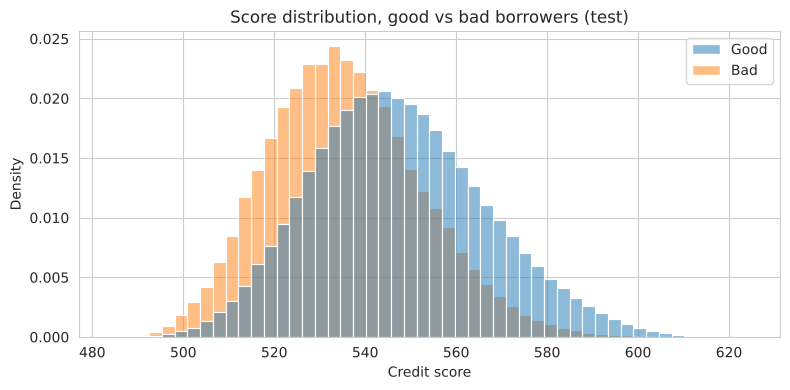

Bad rate by score decile (0 = lowest scores):
0    31.44
1    24.03
2    20.20
3    17.28
4    15.27
5    13.12
6    10.76
7     9.34
8     6.71
9     3.63


In [38]:
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)
n_feats = len(features)
intercept = logit_model.params['const']

rows = []
for col in features:
    b = logit_model.params[col]
    for bin_label, woe in woe_maps[col].items():
        points = -(b * woe + intercept / n_feats) * factor + offset / n_feats
        rows.append({'feature': col, 'bin': bin_label, 'woe': round(woe, 3), 'points': round(points)})
scorecard = pd.DataFrame(rows)
display(scorecard[scorecard['feature'] == 'fico_range_low'])

test_scores = offset - factor * np.log(p_test_logit / (1 - p_test_logit))

plt.figure(figsize=(8, 4))
sns.histplot(x=test_scores, hue=y_test.map({0: 'Good', 1: 'Bad'}).values,
             bins=50, stat='density', common_norm=False)
plt.title('Score distribution, good vs bad borrowers (test)')
plt.xlabel('Credit score')
plt.tight_layout()
save('09_score_distribution')
plt.show()

score_dec = pd.qcut(test_scores, 10, labels=False, duplicates='drop')
print('Bad rate by score decile (0 = lowest scores):')
print((pd.Series(y_test.values).groupby(score_dec).mean() * 100).round(2).to_string())

## 20. Risk bands

Applicants are grouped by PD into four bands (40% / 30% / 20% / 10% of the population, riskiest last).

| Band | Suggested treatment |
|---|---|
| Low | Fast-track approval, best pricing |
| Medium | Approve with standard risk-based pricing |
| High | Approve with higher pricing or lower limit |
| Very high | Manual review or decline |

A growing share of applicants in the Very high band is an early warning that the applicant population is deteriorating.

,loans,defaults,predicted_pd,observed_bad_rate,% of loans,% of all defaults
band,,,,,,
Low,149125,11353,0.0678,0.0761,40.0,20.1
Medium,111842,17029,0.1311,0.1523,30.0,30.1
High,74563,16488,0.1928,0.2211,20.0,29.1
Very high,37281,11721,0.2830,0.3144,10.0,20.7


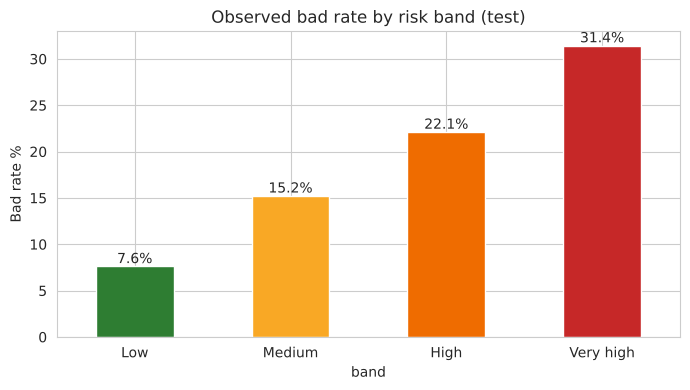

In [39]:
bands = pd.qcut(test_eval['pd'], [0, 0.4, 0.7, 0.9, 1.0], labels=['Low', 'Medium', 'High', 'Very high'])
band_table = (test_eval.assign(band=bands)
              .groupby('band', observed=True)
              .agg(loans=('target', 'size'), defaults=('target', 'sum'),
                   predicted_pd=('pd', 'mean'), observed_bad_rate=('target', 'mean')))
band_table['% of loans'] = (band_table['loans'] / band_table['loans'].sum() * 100).round(1)
band_table['% of all defaults'] = (band_table['defaults'] / band_table['defaults'].sum() * 100).round(1)
display(band_table.round(4))

ax = (band_table['observed_bad_rate'] * 100).plot(kind='bar', figsize=(7, 4),
                                                  color=['#2E7D32', '#F9A825', '#EF6C00', '#C62828'])
for i, v in enumerate(band_table['observed_bad_rate'] * 100):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')
plt.title('Observed bad rate by risk band (test)')
plt.ylabel('Bad rate %')
plt.xticks(rotation=0)
plt.tight_layout()
save('10_risk_bands')
plt.show()

**Findings.** The observed bad rate rises in every band, from 7.6% (Low) to 31.4% (Very high). The riskiest 30% of applicants (High and Very high) account for 49.8% of all defaults.

## 21. Expected loss and Basel capital

### 21.1 LGD and EAD from historical defaults

Measured on **defaulted training loans** only:

- **EAD** (Exposure at Default) = principal outstanding at charge-off = `funded_amnt − total_rec_prncp`
- **LGD** (Loss Given Default) = 1 − (recoveries − collection fees) ÷ EAD, weighted by amount

For new loans the default date is unknown, so EAD = `loan_amnt × exposure ratio`, where the exposure ratio is the average share of the loan outstanding at default. A single portfolio-level LGD and exposure ratio are used and recoveries are not discounted.

In [40]:
defaulted = train[train['target'] == 1]
ead_at_default = (defaulted['funded_amnt'] - defaulted['total_rec_prncp']).clip(lower=0)
net_recovery = (defaulted['recoveries'] - defaulted['collection_recovery_fee']).clip(lower=0)
has_exposure = ead_at_default > 0

LGD = 1 - net_recovery[has_exposure].sum() / ead_at_default[has_exposure].sum()
EXPOSURE_RATIO = ead_at_default[has_exposure].sum() / defaulted.loc[has_exposure, 'funded_amnt'].sum()

print(f'Defaulted training loans  : {has_exposure.sum():,}')
print(f'LGD (amount-weighted)     : {LGD:.1%}')
print(f'Exposure ratio at default : {EXPOSURE_RATIO:.1%} of the original loan')

Defaulted training loans  : 34,693
LGD (amount-weighted)     : 88.6%
Exposure ratio at default : 57.2% of the original loan


### 21.2 Predicted expected loss against actual loss

Loans from the recalibration evaluation period (Jul 2015 to Mar 2016) are scored with the recalibrated PDs. Expected loss = PD × LGD × EAD; actual loss = principal outstanding at default less net recoveries. Both cover the life of the loan.

In [41]:
loss = pd.DataFrame({'band': bands.values, 'target': y_arr, 'pd': p_test_cal,
                     'loan_amnt': test['loan_amnt'].values})
loss['ead'] = loss['loan_amnt'] * EXPOSURE_RATIO
loss['expected_loss'] = loss['pd'] * LGD * loss['ead']

actual = (test['funded_amnt'] - test['total_rec_prncp']
          - (test['recoveries'] - test['collection_recovery_fee']).clip(lower=0)).clip(lower=0)
loss['actual_loss'] = np.where(loss['target'] == 1, actual, 0)

loss = loss[eval_mask]

print(f"Predicted expected loss : ${loss['expected_loss'].sum():,.0f}")
print(f"Actual loss             : ${loss['actual_loss'].sum():,.0f}")
print(f"Ratio actual / predicted: {loss['actual_loss'].sum() / loss['expected_loss'].sum():.2f}")

Predicted expected loss : $226,596,750
Actual loss             : $264,253,283
Ratio actual / predicted: 1.17


### 21.3 Basel IRB capital

Basel formula for **other retail exposures**, which sets capital to cover losses up to the 99.9th percentile:

- Correlation: R = 0.03 × w + 0.16 × (1 − w), where w = (1 − e^(−35 × PD)) ÷ (1 − e^(−35))
- Capital per unit of exposure: K = LGD × [ N( (N⁻¹(PD) + √R × N⁻¹(0.999)) ÷ √(1 − R) ) − PD ]
- Risk-weighted assets: RWA = 12.5 × K × EAD

N is the standard normal distribution. Basel requires a 12-month PD while this model predicts lifetime PD over 36 months, so PD₁₂ₘ = 1 − (1 − PD_lifetime)^(1/3), assuming a constant annual default rate. The Basel PD floor of 0.03% is applied.

,loans,exposure,expected_loss,actual_loss,capital,rwa,EL % of exposure,Actual loss %,Capital % of exposure,RWA density %
band,,,,,,,,,,
Low,103770,862873274.5,55418497.6,59872168.9,80083562.3,1.001045e+09,6.4,6.9,9.3,116.0
Medium,75394,534237720.5,67773934.6,79248695.4,55882910.0,6.985364e+08,12.7,14.8,10.5,130.8
High,49073,327615044.5,60853748.6,72697509.0,36277866.9,4.534733e+08,18.6,22.2,11.1,138.4
Very high,23784,157811703.9,42550569.5,52434909.9,19695196.9,2.461900e+08,27.0,33.2,12.5,156.0


Portfolio: EL 12.04% of exposure, capital 10.20%, RWA density 127%


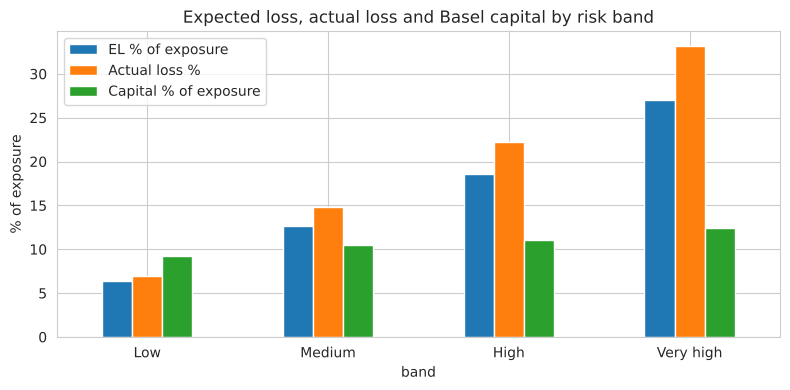

In [42]:
def basel_retail_capital(pd_12m, lgd):
    pd_12m = np.clip(pd_12m, 0.0003, 0.9999)                        # Basel PD floor
    w = (1 - np.exp(-35 * pd_12m)) / (1 - np.exp(-35))
    r = 0.03 * w + 0.16 * (1 - w)                                    # asset correlation
    stressed_pd = norm.cdf((norm.ppf(pd_12m) + np.sqrt(r) * norm.ppf(0.999)) / np.sqrt(1 - r))
    return lgd * (stressed_pd - pd_12m)                              # capital per unit of exposure

loss['pd_12m'] = 1 - (1 - loss['pd']) ** (1 / 3)
loss['capital'] = basel_retail_capital(loss['pd_12m'], LGD) * loss['ead']
loss['rwa'] = 12.5 * loss['capital']

band_money = loss.groupby('band', observed=True).agg(
    loans=('target', 'size'), exposure=('ead', 'sum'),
    expected_loss=('expected_loss', 'sum'), actual_loss=('actual_loss', 'sum'),
    capital=('capital', 'sum'), rwa=('rwa', 'sum'))
band_money['EL % of exposure'] = band_money['expected_loss'] / band_money['exposure'] * 100
band_money['Actual loss %'] = band_money['actual_loss'] / band_money['exposure'] * 100
band_money['Capital % of exposure'] = band_money['capital'] / band_money['exposure'] * 100
band_money['RWA density %'] = band_money['rwa'] / band_money['exposure'] * 100
display(band_money.round(1))

total = band_money.sum()
print(f"Portfolio: EL {total['expected_loss'] / total['exposure']:.2%} of exposure, "
      f"capital {total['capital'] / total['exposure']:.2%}, RWA density {total['rwa'] / total['exposure']:.0%}")

band_money[['EL % of exposure', 'Actual loss %', 'Capital % of exposure']].plot(kind='bar', figsize=(8, 4))
plt.title('Expected loss, actual loss and Basel capital by risk band')
plt.ylabel('% of exposure')
plt.xticks(rotation=0)
plt.tight_layout()
save('11_expected_loss_and_capital')
plt.show()

**Findings.** LGD is 88.6% and loans are on average 57.2% outstanding at default, typical of unsecured lending with low recoveries. Actual losses were 1.17 times the predicted expected loss, because the recalibrated PD is still slightly low (14.3% against 15.2%) and a single portfolio LGD and exposure ratio do not adjust for drift. Expected loss rises from 6.4% of exposure in the Low band to 27.0% in the Very high band, and Basel capital from 9.3% to 12.5% (RWA density 116% to 156%). For risk-based pricing, each band's interest rate must cover its expected loss, the cost of the capital it consumes and operating costs.

## 22. Benchmarking and leakage test

### 22.1 Single-variable benchmarks

LendingClub's grade and interest rate come from its own underwriting model, which used information not in the public file. Comparing them with the scorecard shows how much of that information the scorecard recovers from application data alone.

In [43]:
def single_auc(score):
    score = pd.Series(np.asarray(score, dtype=float))
    mask = score.notna().values
    return roc_auc_score(y_test.values[mask], score.values[mask])

grade_num = test['grade'].map({g: i for i, g in enumerate('ABCDEFG', start=1)})
int_rate_num = pd.to_numeric(test['int_rate'].astype(str).str.rstrip('%'), errors='coerce')

benchmark = pd.Series({
    'Scorecard (application data only)': single_auc(p_test_logit),
    'FICO alone': single_auc(-test['fico_range_low']),
    "LendingClub grade alone": single_auc(grade_num),
    "LendingClub interest rate alone": single_auc(int_rate_num)})
display(benchmark.to_frame('AUC').assign(Gini=lambda d: 2 * d['AUC'] - 1).round(4))

,AUC,Gini
Scorecard (application data only),0.6763,0.3526
FICO alone,0.6036,0.2072
LendingClub grade alone,0.6709,0.3417
LendingClub interest rate alone,0.6823,0.3645


### 22.2 Leakage test

Many public LendingClub projects report AUC above 0.9. To quantify why, the default XGBoost from section 11 is refitted with the shortcuts commonly found in those projects added one at a time, on the same out-of-time split.

In [44]:
def add_columns(X, data, extra):
    X = X.copy()
    for name, values in extra.items():
        X[name] = values(data)
    return X

shortcuts = {
    '+ LendingClub grade and interest rate': {
        'grade_num': lambda d: d['grade'].map({g: i for i, g in enumerate('ABCDEFG', start=1)}),
        'int_rate_num': lambda d: pd.to_numeric(d['int_rate'].astype(str).str.rstrip('%'), errors='coerce')},
    '+ FICO pulled after the loan was issued': {
        'last_fico': lambda d: d['last_fico_range_high']},
    '+ payment and recovery columns': {
        'total_pymnt': lambda d: d['total_pymnt'], 'total_rec_prncp': lambda d: d['total_rec_prncp'],
        'recoveries': lambda d: d['recoveries']}}

leak_rows = [{'Model inputs': 'Application data only (this project)', 'AUC': roc_auc_score(y_test, p_test_xgb_base)}]
extra = {}
for label, cols in shortcuts.items():
    extra.update(cols)                      # each row adds to the previous one
    Xtr, Xte = add_columns(X_train_raw, train, extra), add_columns(X_test_raw, test, extra)
    m = XGBClassifier(**xgb_base.get_params()).fit(Xtr, y_train)
    leak_rows.append({'Model inputs': label, 'AUC': roc_auc_score(y_test, m.predict_proba(Xte)[:, 1])})

leak_table = pd.DataFrame(leak_rows).set_index('Model inputs')
leak_table['Gini'] = 2 * leak_table['AUC'] - 1
display(leak_table.round(4))

,AUC,Gini
Model inputs,,
Application data only (this project),0.6936,0.3872
+ LendingClub grade and interest rate,0.7070,0.4141
+ FICO pulled after the loan was issued,0.9465,0.8930
+ payment and recovery columns,0.9998,0.9996


**Findings.** Using application data only, the scorecard (AUC 0.676) matches LendingClub's own grade (0.671) and comes close to its interest rate (0.682); FICO alone reaches 0.604. In the leakage test, adding grade and interest rate lifts XGBoost from 0.694 to 0.707. Adding the FICO score pulled after issue raises AUC to 0.947, and payment and recovery columns push it to 1.000. Those inputs are not available when an application is decided, which explains the very high scores reported by many public projects on this dataset. Independent leakage-free, out-of-time studies report similar results, for example AUC 0.696 ([credit-risk-scorecard](https://github.com/meghajoshi-ds/credit-risk-scorecard)) and 0.708 ([LendingClub OOT report](https://www.k-dense.ai/examples/session_20260711_204829_f89367ad6d2d/writing_outputs/final/LendingClub_OOT_Default_Prediction_Report.pdf)).

## 23. Limitations and next steps

**Limitations**

1. Marketplace lending data rather than a bank's own underwriting data.
2. The full-observation rule limits usable vintages to Q1 2016 and earlier.
3. The scope is the 36-month product only.
4. The target is lifetime default; Basel and IFRS 9 Stage 1 use a 12-month PD, so the capital calculation relies on an approximate conversion.
5. Recalibration is fitted on a period whose outcomes a lender would not yet fully observe in practice.
6. LGD and EAD are portfolio averages.
7. Rejected applicants are not in the data (reject inference is not possible).
8. No macroeconomic variables.

**Next steps**

- Segment-level LGD and EAD models
- Monotonic constraints for the XGBoost challenger
- Coarse classing to merge adjacent bins with similar WoE
- Macroeconomic overlays for forward-looking IFRS 9 PDs
- A monitoring pack: PSI, CSI, Gini and calibration by vintage

## 24. Model artefacts and scoring function

The bin edges, WoE maps, coefficients and scaling parameters are saved so the full pipeline (bin → WoE → logistic) can score a new application.

In [45]:
os.makedirs('artefacts', exist_ok=True)

scorecard_bundle = {'features': features,
                    'bin_edges': {c: bin_edges[c] for c in features if c in bin_edges},
                    'woe_maps': {c: woe_maps[c] for c in features},
                    'coefficients': logit_model.params,
                    'recalibration_shift': shift,
                    'scaling': {'PDO': PDO, 'base_score': BASE_SCORE, 'base_odds': BASE_ODDS}}
joblib.dump(scorecard_bundle, 'artefacts/pd_scorecard.pkl')
joblib.dump(best_xgb, 'artefacts/xgb_challenger.pkl')
scorecard.to_csv('artefacts/scorecard_points.csv', index=False)
print('Saved:', sorted(os.listdir('artefacts')))

def predict_pd(new_loans):
    # new_loans must contain the raw application fields and the engineered features from section 8
    binned = pd.DataFrame(index=new_loans.index)
    for col in features:
        if col in bin_edges:
            binned[col] = bin_feature(new_loans[col], bin_edges[col])
        else:
            binned[col] = new_loans[col].fillna('Missing').astype(str)
    X = to_woe(binned, features)
    raw_pd = logit_model.predict(sm.add_constant(X, has_constant='add'))
    return expit(log_odds(raw_pd) + shift)          # recalibrated PD

example = test.head(5).copy()
example['PD'] = predict_pd(example).round(4).values
example['score'] = (offset - factor * np.log(example['PD'] / (1 - example['PD']))).round(0)
display(example[['loan_amnt', 'annual_inc', 'fico_range_low', 'dti', 'PD', 'score']])

Saved: ['pd_scorecard.pkl', 'scorecard_points.csv', 'xgb_challenger.pkl']


,loan_amnt,annual_inc,fico_range_low,dti,PD,score
0,3600.0,55000.0,675.0,5.91,0.1162,546.0
1,24700.0,65000.0,715.0,16.06,0.2053,526.0
2,11950.0,34000.0,690.0,10.20,0.1693,533.0
3,20000.0,180000.0,680.0,14.67,0.0964,552.0
4,20000.0,85000.0,705.0,17.61,0.0652,564.0


## Conclusion

A leakage-controlled PD scorecard was built on a censoring-aware universe of fully observed 36-month LendingClub loans, trained on 2013 and 2014 originations and validated out-of-time on 2015 to Q1 2016.

- **Performance:** AUC 0.676, Gini 0.353 and KS 0.254, in line with LendingClub's own grade and with published leakage-free benchmarks.
- **Model choice:** tuned XGBoost adds 3.7 Gini points (statistically significant); the scorecard is retained as champion for interpretability and stability.
- **Class imbalance:** rebalancing did not improve ranking and inflated the mean PD from 13% to 47%, so imbalance is handled through the cut-off.
- **Business use:** at a 70% approval rate the bad rate falls from 15.2% to 10.9%, and the riskiest 30% of applicants hold half of all defaults.
- **Stability and calibration:** score PSI of 0.002 and stable Gini across periods; base-rate drift is corrected by an intercept shift.
- **Losses and capital:** expected loss of 12.0% and Basel IRB capital of 10.2% of exposure, rising consistently across risk bands.